
# Logistics Intelligence & Decision Support

## NexaLog Brasil — Data Science Project

**Projeto:** 05/05 — Professional Data Science Portfolio  
**Área:** Supply Chain & Logistics  
**Metodologia:** CRISP-DM  
**Fonte:** Brazilian E-Commerce Public Dataset by Olist  

---

## Sprint 0 — Business Understanding & Data Feasibility

### 0.1 — Environment Setup & Data Acquisition

#### Contexto empresarial

A NexaLog Brasil é uma empresa fictícia de logística
que necessita melhorar a pontualidade das entregas
e priorizar pedidos com maior risco de atraso.

#### Objetivo do projeto

Desenvolver uma solução de inteligência logística
que combine análise de dados, Machine Learning
e apoio à decisão operacional.

#### Objetivo desta etapa

- Validar o ambiente de desenvolvimento.
- Verificar as dependências instaladas.
- Confirmar a disponibilidade dos arquivos originais.
- Realizar o inventário inicial dos dados.

#### Fonte de dados

Olist — Brazilian E-Commerce Public Dataset.

https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce

Licença: CC BY-NC-SA 4.0.

Os dados são reais e anonimizados.
A empresa NexaLog Brasil é fictícia.
O projeto possui finalidade educacional e demonstrativa.


In [1]:

# ============================================================
# SPRINT 0 — AULA 01
# Environment Setup & Data Acquisition
# ============================================================

from pathlib import Path
from importlib.metadata import version
import sys
import pandas as pd


# ------------------------------------------------------------
# 1. Identificação da raiz do projeto
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"


# ------------------------------------------------------------
# 2. Validação do ambiente
# ------------------------------------------------------------

print("=" * 65)
print("NEXALOG BRASIL | ENVIRONMENT VALIDATION")
print("=" * 65)

print(f"\nPython: {sys.version.split()[0]}")
print(f"Interpretador: {sys.executable}")
print(f"Raiz do projeto: {PROJECT_ROOT}")

packages = [
    "pandas",
    "numpy",
    "scikit-learn",
    "matplotlib",
    "plotly",
    "streamlit",
    "joblib",
    "ipykernel",
    "pytest",
]

print("\nDEPENDÊNCIAS INSTALADAS")

for package in packages:
    print(f"{package:<18} {version(package)}")


# ------------------------------------------------------------
# 3. Inventário dos arquivos esperados
# ------------------------------------------------------------

expected_files = [
    "olist_customers_dataset.csv",
    "olist_geolocation_dataset.csv",
    "olist_order_items_dataset.csv",
    "olist_order_payments_dataset.csv",
    "olist_order_reviews_dataset.csv",
    "olist_orders_dataset.csv",
    "olist_products_dataset.csv",
    "olist_sellers_dataset.csv",
    "product_category_name_translation.csv",
]

inventory = []

for filename in expected_files:

    filepath = RAW_DIR / filename
    exists = filepath.is_file()

    size_mb = (
        filepath.stat().st_size / (1024 ** 2)
        if exists else 0
    )

    inventory.append({
        "arquivo": filename,
        "encontrado": exists,
        "tamanho_mb": round(size_mb, 2),
        "status": (
            "OK" if exists and size_mb > 0
            else "PENDENTE"
        ),
    })

df_inventory = pd.DataFrame(inventory)


# ------------------------------------------------------------
# 4. Exibição do inventário
# ------------------------------------------------------------

print("\n" + "=" * 65)
print("INVENTÁRIO DOS DADOS")
print("=" * 65)

display(df_inventory)

total_files = len(expected_files)

valid_files = int(
    df_inventory["status"].eq("OK").sum()
)

total_size = df_inventory["tamanho_mb"].sum()

print(f"\nArquivos esperados: {total_files}")
print(f"Arquivos válidos: {valid_files}")
print(f"Volume total: {total_size:.2f} MB")


# ------------------------------------------------------------
# 5. Validação final
# ------------------------------------------------------------

print("\n" + "=" * 65)

if valid_files == total_files:
    print("VALIDAÇÃO INICIAL: APROVADA")
    print("Todos os arquivos esperados estão disponíveis.")
else:
    print("VALIDAÇÃO INICIAL: PENDENTE")
    print("Verifique os arquivos ausentes ou vazios.")

print("=" * 65)


NEXALOG BRASIL | ENVIRONMENT VALIDATION

Python: 3.14.10
Interpretador: g:\Desktop\PROJETOS\logistics-intelligence\.venv\Scripts\python.exe
Raiz do projeto: G:\Desktop\PROJETOS\logistics-intelligence

DEPENDÊNCIAS INSTALADAS
pandas             3.1.1
numpy              2.5.5
scikit-learn       1.9.1
matplotlib         3.11.2
plotly             7.1.0
streamlit          1.67.0
joblib             1.6.0
ipykernel          7.4.0
pytest             9.2.0

INVENTÁRIO DOS DADOS


,arquivo,encontrado,tamanho_mb,status
0,olist_customers_dataset.csv,True,8.62,OK
1,olist_geolocation_dataset.csv,True,58.44,OK
2,olist_order_items_dataset.csv,True,14.72,OK
3,olist_order_payments_dataset.csv,True,5.51,OK
4,olist_order_reviews_dataset.csv,True,13.78,OK
5,olist_orders_dataset.csv,True,16.84,OK
6,olist_products_dataset.csv,True,2.27,OK
7,olist_sellers_dataset.csv,True,0.17,OK
8,product_category_name_translation.csv,True,0.00,OK



Arquivos esperados: 9
Arquivos válidos: 9
Volume total: 120.35 MB

VALIDAÇÃO INICIAL: APROVADA
Todos os arquivos esperados estão disponíveis.



---

### 0.2 — Data Understanding & Quality Audit

#### Objetivo empresarial

Avaliar a qualidade estrutural dos dados disponíveis
antes de iniciar a integração das tabelas e o
desenvolvimento da solução preditiva.

#### Objetivos técnicos

- Identificar a dimensão de cada tabela.
- Verificar valores ausentes.
- Identificar registros completamente duplicados.
- Validar as chaves primárias esperadas.
- Comparar os volumes com os registros de referência.
- Monitorar o consumo de memória.

#### Granularidade do projeto

A unidade de análise será o pedido (order_id).

A integração futura deverá preservar exatamente
uma linha por pedido, evitando multiplicação
indevida de registros.

#### Critérios de aceitação

- Todos os arquivos devem ser legíveis.
- As tabelas devem possuir registros e colunas.
- As chaves primárias esperadas devem ser válidas.
- Divergências e problemas devem ser documentados.

Valores ausentes e duplicidades não serão removidos
automaticamente nesta etapa.

#### Entregável

Relatório consolidado de auditoria estrutural
dos nove arquivos originais da Olist.


In [2]:

# ============================================================
# SPRINT 0 — AULA 02
# Data Understanding & Quality Audit
# ============================================================

import gc
from pathlib import Path

import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Configuração do projeto
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"


# ------------------------------------------------------------
# 2. Metadados e chaves esperadas
# ------------------------------------------------------------

DATASETS = {
    "customers": {
        "arquivo": "olist_customers_dataset.csv",
        "registros_esperados": 99441,
        "chave": ["customer_id"],
    },
    "geolocation": {
        "arquivo": "olist_geolocation_dataset.csv",
        "registros_esperados": 1000163,
        "chave": [],
    },
    "order_items": {
        "arquivo": "olist_order_items_dataset.csv",
        "registros_esperados": 112650,
        "chave": ["order_id", "order_item_id"],
    },
    "order_payments": {
        "arquivo": "olist_order_payments_dataset.csv",
        "registros_esperados": 103886,
        "chave": ["order_id", "payment_sequential"],
    },
    "order_reviews": {
        "arquivo": "olist_order_reviews_dataset.csv",
        "registros_esperados": None,
        "chave": [],
    },
    "orders": {
        "arquivo": "olist_orders_dataset.csv",
        "registros_esperados": 99441,
        "chave": ["order_id"],
    },
    "products": {
        "arquivo": "olist_products_dataset.csv",
        "registros_esperados": 32951,
        "chave": ["product_id"],
    },
    "sellers": {
        "arquivo": "olist_sellers_dataset.csv",
        "registros_esperados": 3095,
        "chave": ["seller_id"],
    },
    "category_translation": {
        "arquivo": "product_category_name_translation.csv",
        "registros_esperados": 71,
        "chave": ["product_category_name"],
    },
}


# ------------------------------------------------------------
# 3. Estruturas para armazenar a auditoria
# ------------------------------------------------------------

audit_results = []
missing_results = []
key_results = []
schema_results = []
read_errors = []

print("=" * 75)
print("NEXALOG BRASIL | DATA QUALITY AUDIT")
print("=" * 75)


# ------------------------------------------------------------
# 4. Auditoria sequencial dos arquivos
# ------------------------------------------------------------

for table_name, config in DATASETS.items():

    filepath = RAW_DIR / config["arquivo"]

    print(f"\nAuditando: {table_name}")

    try:
        df = pd.read_csv(filepath, low_memory=False)

    except Exception as error:

        read_errors.append({
            "tabela": table_name,
            "erro": str(error),
        })

        print(f"ERRO DE LEITURA: {error}")
        continue

    # Dimensão da tabela
    rows, columns = df.shape

    # Valores ausentes
    missing = df.isna().sum()
    total_missing = int(missing.sum())

    total_cells = rows * columns

    missing_pct = (
        total_missing / total_cells * 100
        if total_cells > 0 else 0
    )

    # Duplicidades completas
    duplicates = int(df.duplicated().sum())

    # Consumo de memória
    memory_mb = (
        df.memory_usage(deep=True).sum()
        / (1024 ** 2)
    )

    # Comparação com volume de referência
    expected = config["registros_esperados"]

    if expected is None:
        volume_status = "SEM REFERÊNCIA"
    elif rows == expected:
        volume_status = "OK"
    else:
        volume_status = "DIVERGENTE"

    # Relatório estrutural
    audit_results.append({
        "tabela": table_name,
        "registros": rows,
        "colunas": columns,
        "celulas_ausentes": total_missing,
        "ausentes_pct": round(missing_pct, 2),
        "duplicados": duplicates,
        "memoria_mb": round(memory_mb, 2),
        "volume_status": volume_status,
    })

    # Auditoria de valores ausentes por coluna
    for column in df.columns:

        missing_count = int(missing[column])

        if missing_count > 0:

            missing_results.append({
                "tabela": table_name,
                "coluna": column,
                "ausentes": missing_count,
                "ausentes_pct": round(
                    missing_count / rows * 100, 2
                ) if rows > 0 else 0,
            })

        # Inventário de colunas e tipos
        schema_results.append({
            "tabela": table_name,
            "coluna": column,
            "tipo": str(df[column].dtype),
        })

    # --------------------------------------------------------
    # Validação das chaves primárias esperadas
    # --------------------------------------------------------

    key_columns = config["chave"]

    if not key_columns:

        key_results.append({
            "tabela": table_name,
            "chave": "Não definida",
            "nulos": None,
            "duplicados": None,
            "status": "NÃO APLICÁVEL",
        })

    elif not set(key_columns).issubset(df.columns):

        key_results.append({
            "tabela": table_name,
            "chave": " + ".join(key_columns),
            "nulos": None,
            "duplicados": None,
            "status": "COLUNA AUSENTE",
        })

    else:

        key_nulls = int(
            df[key_columns]
            .isna()
            .any(axis=1)
            .sum()
        )

        key_duplicates = int(
            df.duplicated(
                subset=key_columns
            ).sum()
        )

        key_status = (
            "OK"
            if key_nulls == 0
            and key_duplicates == 0
            else "REVISAR"
        )

        key_results.append({
            "tabela": table_name,
            "chave": " + ".join(key_columns),
            "nulos": key_nulls,
            "duplicados": key_duplicates,
            "status": key_status,
        })

    print(
        f"Registros: {rows:,} | "
        f"Colunas: {columns} | "
        f"Memória: {memory_mb:.2f} MB"
    )

    # Liberação de memória antes da próxima tabela
    del df
    gc.collect()


# ------------------------------------------------------------
# 5. Consolidação dos relatórios
# ------------------------------------------------------------

df_audit = pd.DataFrame(audit_results)

df_missing = pd.DataFrame(
    missing_results,
    columns=[
        "tabela",
        "coluna",
        "ausentes",
        "ausentes_pct",
    ],
)

df_keys = pd.DataFrame(key_results)
df_schema = pd.DataFrame(schema_results)
df_read_errors = pd.DataFrame(read_errors)


# ------------------------------------------------------------
# 6. Relatório estrutural
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RELATÓRIO 1 — AUDITORIA ESTRUTURAL")
print("=" * 75)

display(df_audit)


# ------------------------------------------------------------
# 7. Relatório de valores ausentes
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RELATÓRIO 2 — VALORES AUSENTES")
print("=" * 75)

if not df_missing.empty:

    df_missing = df_missing.sort_values(
        "ausentes_pct",
        ascending=False,
    ).reset_index(drop=True)

    display(df_missing)

else:
    print("Nenhum valor ausente identificado.")


# ------------------------------------------------------------
# 8. Relatório de chaves primárias
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RELATÓRIO 3 — INTEGRIDADE DAS CHAVES")
print("=" * 75)

display(df_keys)


# ------------------------------------------------------------
# 9. Validação estrutural final
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RESULTADO DA AUDITORIA")
print("=" * 75)

tables_expected = len(DATASETS)
tables_read = len(df_audit)

valid_dimensions = (
    not df_audit.empty
    and df_audit["registros"].gt(0).all()
    and df_audit["colunas"].gt(0).all()
)

volume_divergences = (
    int(df_audit["volume_status"]
        .eq("DIVERGENTE").sum())
    if not df_audit.empty else 0
)

key_problems = (
    int(
        (~df_keys["status"].isin(
            ["OK", "NÃO APLICÁVEL"]
        )).sum()
    )
    if not df_keys.empty else 0
)

print(f"Tabelas esperadas: {tables_expected}")
print(f"Tabelas auditadas: {tables_read}")
print(f"Erros de leitura: {len(read_errors)}")
print(f"Divergências de volume: {volume_divergences}")
print(f"Problemas nas chaves: {key_problems}")
print(f"Dimensões válidas: {valid_dimensions}")

if read_errors:
    display(df_read_errors)

structural_approved = (
    tables_read == tables_expected
    and len(read_errors) == 0
    and valid_dimensions
    and volume_divergences == 0
    and key_problems == 0
)

print("\n" + "=" * 75)

if structural_approved:
    print("AUDITORIA ESTRUTURAL: APROVADA")
    print("Prosseguir para a auditoria de negócio.")
else:
    print("AUDITORIA ESTRUTURAL: REVISÃO NECESSÁRIA")
    print("Investigar as divergências identificadas.")

print("=" * 75)


NEXALOG BRASIL | DATA QUALITY AUDIT

Auditando: customers
Registros: 99,441 | Colunas: 5 | Memória: 11.03 MB

Auditando: geolocation
Registros: 1,000,163 | Colunas: 5 | Memória: 50.12 MB

Auditando: order_items
Registros: 112,650 | Colunas: 7 | Memória: 18.37 MB

Auditando: order_payments
Registros: 103,886 | Colunas: 5 | Memória: 8.11 MB

Auditando: order_reviews
Registros: 99,224 | Colunas: 7 | Memória: 17.84 MB

Auditando: orders
Registros: 99,441 | Colunas: 8 | Memória: 21.95 MB

Auditando: products
Registros: 32,951 | Colunas: 9 | Memória: 3.73 MB

Auditando: sellers
Registros: 3,095 | Colunas: 4 | Memória: 0.22 MB

Auditando: category_translation
Registros: 71 | Colunas: 2 | Memória: 0.00 MB

RELATÓRIO 1 — AUDITORIA ESTRUTURAL


,tabela,registros,colunas,celulas_ausentes,ausentes_pct,duplicados,memoria_mb,volume_status
0,customers,99441,5,0,0.00,0,11.03,OK
1,geolocation,1000163,5,0,0.00,261831,50.12,OK
2,order_items,112650,7,0,0.00,0,18.37,OK
3,order_payments,103886,5,0,0.00,0,8.11,OK
4,order_reviews,99224,7,145903,21.01,0,17.84,SEM REFERÊNCIA
5,orders,99441,8,4908,0.62,0,21.95,OK
6,products,32951,9,2448,0.83,0,3.73,OK
7,sellers,3095,4,0,0.00,0,0.22,OK
8,category_translation,71,2,0,0.00,0,0.00,OK



RELATÓRIO 2 — VALORES AUSENTES


,tabela,coluna,ausentes,ausentes_pct
0,order_reviews,review_comment_title,87656,88.34
1,order_reviews,review_comment_message,58247,58.70
2,orders,order_delivered_customer_date,2965,2.98
3,products,product_name_lenght,610,1.85
4,products,product_category_name,610,1.85
5,products,product_description_lenght,610,1.85
6,products,product_photos_qty,610,1.85
7,orders,order_delivered_carrier_date,1783,1.79
8,orders,order_approved_at,160,0.16
9,products,product_weight_g,2,0.01



RELATÓRIO 3 — INTEGRIDADE DAS CHAVES


,tabela,chave,nulos,duplicados,status
0,customers,customer_id,0.0,0.0,OK
1,geolocation,Não definida,NaN,NaN,NÃO APLICÁVEL
2,order_items,order_id + order_item_id,0.0,0.0,OK
3,order_payments,order_id + payment_sequential,0.0,0.0,OK
4,order_reviews,Não definida,NaN,NaN,NÃO APLICÁVEL
5,orders,order_id,0.0,0.0,OK
6,products,product_id,0.0,0.0,OK
7,sellers,seller_id,0.0,0.0,OK
8,category_translation,product_category_name,0.0,0.0,OK



RESULTADO DA AUDITORIA
Tabelas esperadas: 9
Tabelas auditadas: 9
Erros de leitura: 0
Divergências de volume: 0
Problemas nas chaves: 0
Dimensões válidas: True

AUDITORIA ESTRUTURAL: APROVADA
Prosseguir para a auditoria de negócio.



---

### 0.3 — Target Definition & Business Rules

#### Objetivo empresarial

Definir uma população de pedidos elegíveis para
o desenvolvimento de um modelo de previsão
de atrasos nas entregas.

#### Objetivos técnicos

- Investigar os status dos pedidos.
- Validar as datas operacionais.
- Identificar inconsistências cronológicas.
- Definir a população elegível.
- Construir a variável-alvo is_late.
- Calcular a prevalência histórica de atrasos.
- Investigar a distribuição temporal dos pedidos.

#### Regras de negócio

1. A unidade de análise será o pedido.
2. Apenas pedidos entregues serão elegíveis.
3. As datas obrigatórias deverão ser válidas.
4. A aprovação não poderá anteceder a compra.
5. A entrega não poderá anteceder a aprovação.
6. A data prometida não poderá anteceder a compra.
7. A previsão será realizada na aprovação do pedido.
8. A data efetiva de entrega será utilizada
   exclusivamente para construir o alvo histórico.

#### Definição da variável-alvo

- is_late = 0: entrega no prazo ou antecipada.
- is_late = 1: entrega após o dia prometido.

A comparação será realizada por dia de calendário,
desconsiderando o horário da entrega.

#### Critérios preliminares de viabilidade

- Pelo menos 10.000 pedidos elegíveis.
- Pelo menos 1.000 pedidos atrasados.
- Pelo menos 1.000 pedidos entregues no prazo.
- Ausência de duplicidades na chave order_id.
- Variável-alvo binária e sem valores ausentes.

Esses critérios são condições preliminares de
volume e qualidade, não garantias de capacidade
preditiva.

#### Entregável

Base candidata de pedidos elegíveis e relatório
de distribuição da variável-alvo.


NEXALOG BRASIL | TARGET DEFINITION

Total de pedidos: 99,441
Total de colunas: 8

RELATÓRIO 1 — STATUS DOS PEDIDOS


,status,pedidos,percentual
0,delivered,96478,97.02
1,shipped,1107,1.11
2,canceled,625,0.63
3,unavailable,609,0.61
4,invoiced,314,0.32
5,processing,301,0.30
6,created,5,0.01
7,approved,2,0.00



RELATÓRIO 2 — AUDITORIA DAS DATAS


,coluna,ausentes_originais,datas_invalidas,ausentes_totais,data_minima,data_maxima
0,order_purchase_timestamp,0,0,0,2016-09-04 21:15:19,2018-10-17 17:30:18
1,order_approved_at,160,0,160,2016-09-15 12:16:38,2018-09-03 17:40:06
2,order_delivered_carrier_date,1783,0,1783,2016-10-08 10:34:01,2018-09-11 19:48:28
3,order_delivered_customer_date,2965,0,2965,2016-10-11 13:46:32,2018-10-17 13:22:46
4,order_estimated_delivery_date,0,0,0,2016-09-30 00:00:00,2018-11-12 00:00:00



RELATÓRIO 3 — POPULAÇÃO ELEGÍVEL


,etapa,pedidos_restantes,excluidos_na_etapa,retencao_pct
0,População original,99441,0,100.00
1,Pedidos entregues,96478,2963,97.02
2,Datas obrigatórias válidas,96456,22,97.00
3,Aprovação cronologicamente válida,96456,0,97.00
4,Entrega cronologicamente válida,96395,61,96.94
5,Prazo prometido válido,96395,0,96.94
6,Prazo não vencido na aprovação,96394,1,96.94


... (2 outputs left out)


RELATÓRIO 5 — INDICADORES DE NEGÓCIO


,indicador,valor
0,Pedidos elegíveis,96394.00
1,Pedidos no prazo,89862.00
2,Pedidos atrasados,6532.00
3,OTD (%),93.22
4,Taxa de atraso (%),6.78
5,Tempo médio de entrega (dias),12.56
6,Prazo médio prometido (dias),24.38
7,Atraso médio dos atrasados (dias),10.62



RELATÓRIO 6 — DISTRIBUIÇÃO TEMPORAL


,approval_month,pedidos,atrasados,taxa_atraso_pct
0,2016-09,1,1,100.00
1,2016-10,265,2,0.75
2,2016-12,1,0,0.00
3,2017-01,715,21,2.94
4,2017-02,1638,46,2.81
5,2017-03,2553,118,4.62
6,2017-04,2278,149,6.54
7,2017-05,3547,108,3.04
8,2017-06,3143,95,3.02
9,2017-07,3827,107,2.80


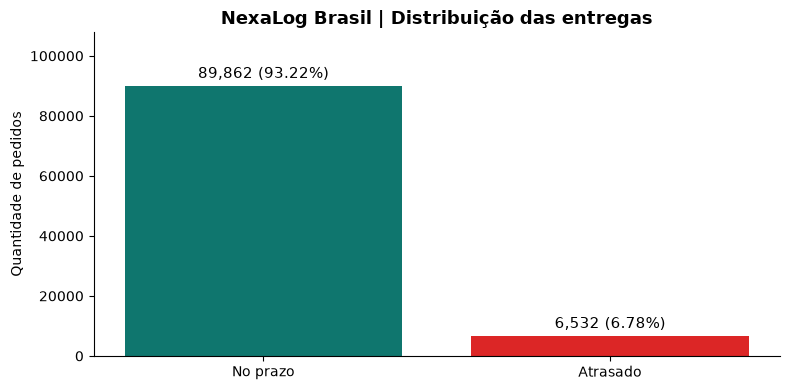


RELATÓRIO 7 — VALIDAÇÃO FINAL


,criterio,status
0,Mínimo de 10.000 pedidos,OK
1,Mínimo de 1.000 atrasados,OK
2,Mínimo de 1.000 no prazo,OK
3,Sem pedidos duplicados,OK
4,Sem identificadores ausentes,OK
5,Alvo sem valores ausentes,OK
6,Alvo binário válido,OK
7,População reconciliada,OK



População original: 99,441
Pedidos excluídos: 3,047
População elegível: 96,394
Pedidos atrasados: 6,532
Taxa de atraso: 6.78%
OTD: 93.22%

VARIÁVEL-ALVO: APROVADA
População candidata validada.
Prosseguir para auditoria das preditoras.


In [3]:

# ============================================================
# SPRINT 0 — AULA 03
# Target Definition & Business Rules
# ============================================================

from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


# ------------------------------------------------------------
# 1. Configuração do projeto
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"

ORDERS_FILE = RAW_DIR / "olist_orders_dataset.csv"


# ------------------------------------------------------------
# 2. Carregamento dos pedidos
# ------------------------------------------------------------

orders = pd.read_csv(
    ORDERS_FILE,
    low_memory=False,
)

total_orders = len(orders)

print("=" * 75)
print("NEXALOG BRASIL | TARGET DEFINITION")
print("=" * 75)

print(f"\nTotal de pedidos: {total_orders:,}")
print(f"Total de colunas: {orders.shape[1]}")


# ------------------------------------------------------------
# 3. Distribuição dos status
# ------------------------------------------------------------

status_summary = (
    orders["order_status"]
    .value_counts(dropna=False)
    .rename_axis("status")
    .reset_index(name="pedidos")
)

status_summary["percentual"] = (
    status_summary["pedidos"]
    / total_orders * 100
).round(2)

print("\n" + "=" * 75)
print("RELATÓRIO 1 — STATUS DOS PEDIDOS")
print("=" * 75)

display(status_summary)


# ------------------------------------------------------------
# 4. Conversão e auditoria das datas
# ------------------------------------------------------------

date_columns = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

date_audit = []

for column in date_columns:

    original_missing = int(
        orders[column].isna().sum()
    )

    orders[column] = pd.to_datetime(
        orders[column],
        errors="coerce",
    )

    final_missing = int(
        orders[column].isna().sum()
    )

    date_audit.append({
        "coluna": column,
        "ausentes_originais": original_missing,
        "datas_invalidas": (
            final_missing - original_missing
        ),
        "ausentes_totais": final_missing,
        "data_minima": orders[column].min(),
        "data_maxima": orders[column].max(),
    })

df_date_audit = pd.DataFrame(date_audit)

print("\n" + "=" * 75)
print("RELATÓRIO 2 — AUDITORIA DAS DATAS")
print("=" * 75)

display(df_date_audit)


# ------------------------------------------------------------
# 5. Seleção sequencial da população elegível
# ------------------------------------------------------------

population_audit = []


def register_population(stage, dataframe, previous):

    current = len(dataframe)

    population_audit.append({
        "etapa": stage,
        "pedidos_restantes": current,
        "excluidos_na_etapa": previous - current,
        "retencao_pct": round(
            current / total_orders * 100, 2
        ),
    })


# População original
register_population(
    "População original",
    orders,
    total_orders,
)


# RN02 — Apenas pedidos entregues
eligible_orders = orders.loc[
    orders["order_status"].eq("delivered")
].copy()

register_population(
    "Pedidos entregues",
    eligible_orders,
    total_orders,
)


# RN03 a RN06 — Datas obrigatórias
required_dates = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_customer_date",
    "order_estimated_delivery_date",
]

previous_count = len(eligible_orders)

eligible_orders = (
    eligible_orders
    .dropna(subset=required_dates)
    .copy()
)

register_population(
    "Datas obrigatórias válidas",
    eligible_orders,
    previous_count,
)


# RN07 — Aprovação posterior ou igual à compra
previous_count = len(eligible_orders)

eligible_orders = eligible_orders.loc[
    eligible_orders["order_approved_at"]
    >= eligible_orders["order_purchase_timestamp"]
].copy()

register_population(
    "Aprovação cronologicamente válida",
    eligible_orders,
    previous_count,
)


# RN07 — Entrega posterior ou igual à aprovação
previous_count = len(eligible_orders)

eligible_orders = eligible_orders.loc[
    eligible_orders["order_delivered_customer_date"]
    >= eligible_orders["order_approved_at"]
].copy()

register_population(
    "Entrega cronologicamente válida",
    eligible_orders,
    previous_count,
)


# RN07 — Dia prometido não anterior à compra
previous_count = len(eligible_orders)

eligible_orders = eligible_orders.loc[
    eligible_orders[
        "order_estimated_delivery_date"
    ].dt.normalize()
    >= eligible_orders[
        "order_purchase_timestamp"
    ].dt.normalize()
].copy()

register_population(
    "Prazo prometido válido",
    eligible_orders,
    previous_count,
)


# A previsão deve ocorrer antes do vencimento
# do prazo prometido.
previous_count = len(eligible_orders)

eligible_orders = eligible_orders.loc[
    eligible_orders[
        "order_approved_at"
    ].dt.normalize()
    <= eligible_orders[
        "order_estimated_delivery_date"
    ].dt.normalize()
].copy()

register_population(
    "Prazo não vencido na aprovação",
    eligible_orders,
    previous_count,
)


df_population_audit = pd.DataFrame(
    population_audit
)

print("\n" + "=" * 75)
print("RELATÓRIO 3 — POPULAÇÃO ELEGÍVEL")
print("=" * 75)

display(df_population_audit)


# ------------------------------------------------------------
# 6. Construção da variável-alvo
# ------------------------------------------------------------

# Comparação por dia de calendário
actual_delivery_day = (
    eligible_orders[
        "order_delivered_customer_date"
    ].dt.normalize()
)

estimated_delivery_day = (
    eligible_orders[
        "order_estimated_delivery_date"
    ].dt.normalize()
)

# Diferença em dias de calendário
eligible_orders["delay_days"] = (
    actual_delivery_day - estimated_delivery_day
).dt.days

# Alvo binário
eligible_orders["is_late"] = (
    eligible_orders["delay_days"] > 0
).astype("int8")

# Tempo total de entrega
eligible_orders["delivery_time_days"] = (
    eligible_orders["order_delivered_customer_date"]
    - eligible_orders["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Prazo prometido em dias de calendário
eligible_orders["promised_days"] = (
    estimated_delivery_day
    - eligible_orders[
        "order_purchase_timestamp"
    ].dt.normalize()
).dt.days


# ------------------------------------------------------------
# 7. Distribuição da variável-alvo
# ------------------------------------------------------------

target_summary = (
    eligible_orders["is_late"]
    .value_counts()
    .reindex([0, 1], fill_value=0)
    .rename_axis("is_late")
    .reset_index(name="pedidos")
)

target_summary["descricao"] = (
    target_summary["is_late"].map({
        0: "No prazo",
        1: "Atrasado",
    })
)

eligible_count = len(eligible_orders)

target_summary["percentual"] = (
    target_summary["pedidos"]
    / eligible_count * 100
).round(2)

print("\n" + "=" * 75)
print("RELATÓRIO 4 — VARIÁVEL-ALVO")
print("=" * 75)

display(target_summary)


# ------------------------------------------------------------
# 8. Indicadores históricos
# ------------------------------------------------------------

late_orders = eligible_orders.loc[
    eligible_orders["is_late"].eq(1)
]

late_count = len(late_orders)

on_time_count = int(
    eligible_orders["is_late"].eq(0).sum()
)

late_rate = (
    late_count / eligible_count * 100
    if eligible_count else float("nan")
)

on_time_rate = (
    on_time_count / eligible_count * 100
    if eligible_count else float("nan")
)

business_kpis = pd.DataFrame({
    "indicador": [
        "Pedidos elegíveis",
        "Pedidos no prazo",
        "Pedidos atrasados",
        "OTD (%)",
        "Taxa de atraso (%)",
        "Tempo médio de entrega (dias)",
        "Prazo médio prometido (dias)",
        "Atraso médio dos atrasados (dias)",
    ],
    "valor": [
        eligible_count,
        on_time_count,
        late_count,
        round(on_time_rate, 2),
        round(late_rate, 2),
        round(
            eligible_orders[
                "delivery_time_days"
            ].mean(), 2
        ),
        round(
            eligible_orders[
                "promised_days"
            ].mean(), 2
        ),
        round(
            late_orders["delay_days"].mean(), 2
        ),
    ],
})

print("\n" + "=" * 75)
print("RELATÓRIO 5 — INDICADORES DE NEGÓCIO")
print("=" * 75)

display(business_kpis)


# ------------------------------------------------------------
# 9. Distribuição temporal
# ------------------------------------------------------------

eligible_orders["approval_month"] = (
    eligible_orders["order_approved_at"]
    .dt.to_period("M")
    .astype(str)
)

monthly_target = (
    eligible_orders
    .groupby("approval_month")
    .agg(
        pedidos=("order_id", "size"),
        atrasados=("is_late", "sum"),
    )
    .reset_index()
)

monthly_target["taxa_atraso_pct"] = (
    monthly_target["atrasados"]
    / monthly_target["pedidos"] * 100
).round(2)

print("\n" + "=" * 75)
print("RELATÓRIO 6 — DISTRIBUIÇÃO TEMPORAL")
print("=" * 75)

display(monthly_target)


# ------------------------------------------------------------
# 10. Visualização da variável-alvo
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 4))

bars = ax.bar(
    target_summary["descricao"],
    target_summary["pedidos"],
    color=["#0F766E", "#DC2626"],
)

for bar, percentage in zip(
    bars,
    target_summary["percentual"],
):

    height = bar.get_height()

    ax.annotate(
        f"{height:,.0f} ({percentage:.2f}%)",
        xy=(
            bar.get_x() + bar.get_width() / 2,
            height,
        ),
        xytext=(0, 6),
        textcoords="offset points",
        ha="center",
        fontsize=11,
    )

ax.set_title(
    "NexaLog Brasil | Distribuição das entregas",
    fontsize=13,
    fontweight="bold",
)

ax.set_ylabel("Quantidade de pedidos")

ax.set_ylim(
    0,
    max(target_summary["pedidos"].max(), 1) * 1.2,
)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 11. Validação da população e do alvo
# ------------------------------------------------------------

duplicate_orders = int(
    eligible_orders["order_id"].duplicated().sum()
)

null_order_ids = int(
    eligible_orders["order_id"].isna().sum()
)

target_nulls = int(
    eligible_orders["is_late"].isna().sum()
)

target_classes = set(
    eligible_orders["is_late"].unique()
)

valid_target = target_classes == {0, 1}

excluded_orders = total_orders - eligible_count

population_reconciled = (
    df_population_audit["excluidos_na_etapa"].sum()
    == excluded_orders
)

validation_checks = {
    "Mínimo de 10.000 pedidos": (
        eligible_count >= 10000
    ),
    "Mínimo de 1.000 atrasados": (
        late_count >= 1000
    ),
    "Mínimo de 1.000 no prazo": (
        on_time_count >= 1000
    ),
    "Sem pedidos duplicados": (
        duplicate_orders == 0
    ),
    "Sem identificadores ausentes": (
        null_order_ids == 0
    ),
    "Alvo sem valores ausentes": (
        target_nulls == 0
    ),
    "Alvo binário válido": valid_target,
    "População reconciliada": population_reconciled,
}

df_target_validation = pd.DataFrame([
    {
        "criterio": criterion,
        "status": "OK" if result else "REVISAR",
    }
    for criterion, result in validation_checks.items()
])

print("\n" + "=" * 75)
print("RELATÓRIO 7 — VALIDAÇÃO FINAL")
print("=" * 75)

display(df_target_validation)

print(f"\nPopulação original: {total_orders:,}")
print(f"Pedidos excluídos: {excluded_orders:,}")
print(f"População elegível: {eligible_count:,}")
print(f"Pedidos atrasados: {late_count:,}")
print(f"Taxa de atraso: {late_rate:.2f}%")
print(f"OTD: {on_time_rate:.2f}%")

print("\n" + "=" * 75)

target_approved = all(validation_checks.values())

if target_approved:

    print("VARIÁVEL-ALVO: APROVADA")
    print("População candidata validada.")
    print("Prosseguir para auditoria das preditoras.")

else:

    print("VARIÁVEL-ALVO: REVISÃO NECESSÁRIA")
    print("Investigar os critérios não atendidos.")

print("=" * 75)



---

### 0.4 — Feature Availability & Data Leakage

#### Objetivo empresarial

Identificar as informações disponíveis no momento
da aprovação do pedido para estimar o risco de
atraso antes da ocorrência do problema.

#### Objetivos técnicos

- Definir o momento de referência da previsão.
- Auditar a disponibilidade das preditoras.
- Identificar variáveis com vazamento de dados.
- Verificar a integridade referencial.
- Agregar os itens na granularidade do pedido.
- Construir uma base preditiva preliminar.
- Avaliar a completude das variáveis.

#### Momento da previsão

A aprovação do pedido será o instante de referência.

Somente informações plausivelmente disponíveis
até esse momento poderão ser utilizadas.

#### Prevenção de Data Leakage

Não serão utilizadas como preditoras:

- Status final do pedido.
- Data efetiva de despacho.
- Data efetiva de entrega.
- Avaliações dos consumidores.
- Dias de atraso.
- Tempo efetivo de entrega.

#### Estratégia inicial

Utilizar as tabelas orders, customers,
order_items, products e sellers.

As informações dos itens serão agregadas
antes da integração com a tabela de pedidos.

#### Limitações

A base pública não possui versões históricas
de todos os atributos cadastrais.

A disponibilidade dos atributos de produto,
vendedor, preço e frete na aprovação será
considerada uma hipótese operacional.

O modelo será condicionado aos pedidos
que eventualmente foram entregues.

#### Critérios de aceitação

- Preservar a granularidade de um pedido.
- Preservar a população elegível.
- Validar os relacionamentos essenciais.
- Não utilizar variáveis futuras.
- Manter a variável-alvo íntegra.
- Documentar valores ausentes.

#### Entregável

Base preditiva candidata para o teste
preliminar de viabilidade de Machine Learning.


In [4]:

# ============================================================
# SPRINT 0 — AULA 04
# Feature Availability & Data Leakage
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd
from IPython.display import display


# ------------------------------------------------------------
# 1. Configuração e pré-requisitos
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

RAW_DIR = PROJECT_ROOT / "data" / "raw"

assert "eligible_orders" in globals(), (
    "Execute a célula de código da Aula 03."
)

assert target_approved, (
    "A variável-alvo precisa estar aprovada."
)

print("=" * 75)
print("NEXALOG BRASIL | FEATURE AVAILABILITY AUDIT")
print("=" * 75)


# ------------------------------------------------------------
# 2. Carregamento seletivo das tabelas
# ------------------------------------------------------------

customers = pd.read_csv(
    RAW_DIR / "olist_customers_dataset.csv",
    usecols=[
        "customer_id",
        "customer_state",
    ],
)

items = pd.read_csv(
    RAW_DIR / "olist_order_items_dataset.csv",
    usecols=[
        "order_id",
        "order_item_id",
        "product_id",
        "seller_id",
        "price",
        "freight_value",
    ],
)

products = pd.read_csv(
    RAW_DIR / "olist_products_dataset.csv",
    usecols=[
        "product_id",
        "product_category_name",
        "product_weight_g",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm",
    ],
)

sellers = pd.read_csv(
    RAW_DIR / "olist_sellers_dataset.csv",
    usecols=[
        "seller_id",
        "seller_state",
    ],
)

print("\nTABELAS CARREGADAS")

for name, table in {
    "customers": customers,
    "items": items,
    "products": products,
    "sellers": sellers,
}.items():

    print(f"{name:<15}: {len(table):,}")


# ------------------------------------------------------------
# 3. Auditoria de integridade referencial
# ------------------------------------------------------------

relationships = [
    (
        "orders → customers",
        orders["customer_id"],
        customers["customer_id"],
    ),
    (
        "items → orders",
        items["order_id"],
        orders["order_id"],
    ),
    (
        "items → products",
        items["product_id"],
        products["product_id"],
    ),
    (
        "items → sellers",
        items["seller_id"],
        sellers["seller_id"],
    ),
    (
        "eligible_orders → items",
        eligible_orders["order_id"],
        items["order_id"],
    ),
]

referential_results = []

for name, source, destination in relationships:

    valid = (
        source.notna()
        & source.isin(destination.dropna())
    )

    unmatched = int((~valid).sum())

    referential_results.append({
        "relacionamento": name,
        "registros": len(source),
        "sem_correspondencia": unmatched,
        "cobertura_pct": round(
            valid.mean() * 100, 2
        ),
        "status": (
            "OK" if unmatched == 0
            else "REVISAR"
        ),
    })

df_referential = pd.DataFrame(
    referential_results
)

print("\n" + "=" * 75)
print("RELATÓRIO 1 — INTEGRIDADE REFERENCIAL")
print("=" * 75)

display(df_referential)


# ------------------------------------------------------------
# 4. Seleção dos itens elegíveis
# ------------------------------------------------------------

eligible_items = items.loc[
    items["order_id"].isin(
        eligible_orders["order_id"]
    )
].copy()

initial_item_count = len(eligible_items)


# ------------------------------------------------------------
# 5. Enriquecimento dos itens
# ------------------------------------------------------------

enriched_items = eligible_items.merge(
    products,
    on="product_id",
    how="left",
    validate="many_to_one",
)

enriched_items = enriched_items.merge(
    sellers,
    on="seller_id",
    how="left",
    validate="many_to_one",
)

assert len(enriched_items) == initial_item_count, (
    "A integração alterou a quantidade de itens."
)


# ------------------------------------------------------------
# 6. Inclusão da localização do cliente
# ------------------------------------------------------------

order_customers = eligible_orders[
    ["order_id", "customer_id"]
].merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
)

enriched_items = enriched_items.merge(
    order_customers[
        ["order_id", "customer_state"]
    ],
    on="order_id",
    how="left",
    validate="many_to_one",
)

assert len(enriched_items) == initial_item_count


# ------------------------------------------------------------
# 7. Auditoria de valores numéricos
# ------------------------------------------------------------

numeric_columns = [
    "price",
    "freight_value",
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm",
]

numeric_audit = []

for column in numeric_columns:

    values = pd.to_numeric(
        enriched_items[column],
        errors="coerce",
    )

    invalid = (
        values.lt(0)
        | (
            values.notna()
            & ~np.isfinite(values)
        )
    )

    # Preço e dimensões devem ser positivos.
    # Frete e peso zero serão mantidos para auditoria.
    if column in [
        "price",
        "product_length_cm",
        "product_height_cm",
        "product_width_cm",
    ]:
        invalid = invalid | values.eq(0)

    numeric_audit.append({
        "variavel": column,
        "ausentes": int(values.isna().sum()),
        "zeros": int(values.eq(0).sum()),
        "invalidos": int(invalid.sum()),
        "minimo": values.min(),
        "maximo": values.max(),
    })

    # Valores inválidos não serão utilizados.
    enriched_items[column] = values.mask(invalid)

df_numeric_audit = pd.DataFrame(
    numeric_audit
)

print("\n" + "=" * 75)
print("RELATÓRIO 2 — QUALIDADE NUMÉRICA")
print("=" * 75)

display(df_numeric_audit)


# ------------------------------------------------------------
# 8. Engenharia de atributos por item
# ------------------------------------------------------------

# Volume físico em centímetros cúbicos
enriched_items["product_volume_cm3"] = (
    enriched_items["product_length_cm"]
    * enriched_items["product_height_cm"]
    * enriched_items["product_width_cm"]
)

# Indicador de transporte interestadual
known_states = (
    enriched_items["seller_state"].notna()
    & enriched_items["customer_state"].notna()
)

enriched_items["interstate_item"] = (
    enriched_items["seller_state"]
    .ne(enriched_items["customer_state"])
    .where(known_states)
    .astype("Float64")
)


# ------------------------------------------------------------
# 9. Agregação na granularidade do pedido
# ------------------------------------------------------------

def complete_sum(series):

    # Evita somar parcialmente atributos ausentes.
    if series.isna().any():
        return np.nan

    return series.sum()


order_features = (
    enriched_items
    .groupby("order_id")
    .agg(
        item_count=(
            "order_item_id", "size"
        ),
        unique_products=(
            "product_id", "nunique"
        ),
        unique_sellers=(
            "seller_id", "nunique"
        ),
        total_price=(
            "price", complete_sum
        ),
        total_freight=(
            "freight_value", complete_sum
        ),
        total_weight_g=(
            "product_weight_g", complete_sum
        ),
        total_volume_cm3=(
            "product_volume_cm3", complete_sum
        ),
        interstate_ratio=(
            "interstate_item", "mean"
        ),
        known_route_items=(
            "interstate_item", "count"
        ),
        unique_categories=(
            "product_category_name", "nunique"
        ),
    )
    .reset_index()
)

# Rotas incompletas não devem ser tratadas
# como se todos os vendedores fossem conhecidos.
incomplete_routes = (
    order_features["known_route_items"]
    != order_features["item_count"]
)

order_features.loc[
    incomplete_routes,
    "interstate_ratio",
] = np.nan

order_features = order_features.drop(
    columns="known_route_items"
)


# ------------------------------------------------------------
# 10. Categoria e vendedor de referência
# ------------------------------------------------------------

# Primeiro item conforme a sequência original.
first_item = (
    enriched_items
    .sort_values([
        "order_id",
        "order_item_id",
    ])
    .drop_duplicates(
        subset="order_id",
        keep="first",
    )
    [[
        "order_id",
        "product_category_name",
        "seller_state",
    ]]
    .rename(columns={
        "product_category_name": (
            "first_item_category"
        ),
        "seller_state": (
            "first_item_seller_state"
        ),
    })
)

order_features = order_features.merge(
    first_item,
    on="order_id",
    how="left",
    validate="one_to_one",
)

# Participação do frete no valor do pedido
total_order_value = (
    order_features["total_price"]
    + order_features["total_freight"]
)

order_features["freight_ratio"] = (
    order_features["total_freight"]
    / total_order_value.replace(0, np.nan)
)


# ------------------------------------------------------------
# 11. Base de pedidos e atributos temporais
# ------------------------------------------------------------

feature_base = eligible_orders[[
    "order_id",
    "customer_id",
    "order_purchase_timestamp",
    "order_approved_at",
    "order_estimated_delivery_date",
    "order_delivered_customer_date",
    "is_late",
]].copy()

purchase = feature_base[
    "order_purchase_timestamp"
]

approval = feature_base[
    "order_approved_at"
]

estimated = feature_base[
    "order_estimated_delivery_date"
]

feature_base["purchase_month"] = (
    purchase.dt.month
)

feature_base["purchase_weekday"] = (
    purchase.dt.dayofweek
)

feature_base["purchase_hour"] = (
    purchase.dt.hour
)

feature_base["approval_hours"] = (
    approval - purchase
).dt.total_seconds() / 3600

feature_base["promised_days"] = (
    estimated.dt.normalize()
    - purchase.dt.normalize()
).dt.days

feature_base["remaining_days"] = (
    estimated.dt.normalize()
    - approval.dt.normalize()
).dt.days


# ------------------------------------------------------------
# 12. Integração final preliminar
# ------------------------------------------------------------

feature_base = feature_base.merge(
    customers,
    on="customer_id",
    how="left",
    validate="many_to_one",
)

feature_base = feature_base.merge(
    order_features,
    on="order_id",
    how="left",
    validate="one_to_one",
)

# Registro de quando o resultado ficou conhecido.
# Será usado somente no controle temporal.
feature_base = feature_base.rename(columns={
    "order_approved_at": "prediction_timestamp",
    "order_delivered_customer_date": (
        "label_available_at"
    ),
})

feature_base = feature_base.drop(columns=[
    "customer_id",
    "order_purchase_timestamp",
    "order_estimated_delivery_date",
])


# ------------------------------------------------------------
# 13. Lista explícita de preditoras permitidas
# ------------------------------------------------------------

NUMERIC_FEATURES = [
    "purchase_month",
    "purchase_weekday",
    "purchase_hour",
    "approval_hours",
    "promised_days",
    "remaining_days",
    "item_count",
    "unique_products",
    "unique_sellers",
    "total_price",
    "total_freight",
    "total_weight_g",
    "total_volume_cm3",
    "interstate_ratio",
    "unique_categories",
    "freight_ratio",
]

CATEGORICAL_FEATURES = [
    "customer_state",
    "first_item_category",
    "first_item_seller_state",
]

FEATURE_COLUMNS = (
    NUMERIC_FEATURES
    + CATEGORICAL_FEATURES
)

TARGET_COLUMN = "is_late"

METADATA_COLUMNS = [
    "order_id",
    "prediction_timestamp",
    "label_available_at",
]

FORBIDDEN_FEATURES = {
    "order_status",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "label_available_at",
    "prediction_timestamp",
    "delay_days",
    "delivery_time_days",
    "review_score",
    "review_comment_title",
    "review_comment_message",
    "is_late",
    "order_id",
    "customer_id",
}

# Somente a lista autorizada poderá alimentar
# o modelo de Machine Learning.
feature_base = feature_base[
    METADATA_COLUMNS
    + FEATURE_COLUMNS
    + [TARGET_COLUMN]
].copy()

X_candidate = feature_base[
    FEATURE_COLUMNS
].copy()

y_candidate = feature_base[
    TARGET_COLUMN
].copy()


# ------------------------------------------------------------
# 14. Auditoria das preditoras
# ------------------------------------------------------------

feature_audit = []

for column in FEATURE_COLUMNS:

    missing_count = int(
        X_candidate[column].isna().sum()
    )

    feature_audit.append({
        "variavel": column,
        "tipo": (
            "Numérica"
            if column in NUMERIC_FEATURES
            else "Categórica"
        ),
        "ausentes": missing_count,
        "ausentes_pct": round(
            missing_count
            / len(X_candidate) * 100,
            2,
        ),
        "valores_distintos": (
            X_candidate[column].nunique()
        ),
    })

df_feature_audit = (
    pd.DataFrame(feature_audit)
    .sort_values(
        "ausentes_pct",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("RELATÓRIO 3 — AUDITORIA DAS PREDITORAS")
print("=" * 75)

display(df_feature_audit)


# ------------------------------------------------------------
# 15. Amostra da base candidata
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RELATÓRIO 4 — BASE PREDITIVA CANDIDATA")
print("=" * 75)

display(
    feature_base[[
        "order_id",
        "customer_state",
        "promised_days",
        "item_count",
        "total_price",
        "total_freight",
        "interstate_ratio",
        "is_late",
    ]].head(10)
)

print(
    f"\nDimensão da base: "
    f"{feature_base.shape}"
)

print(
    f"Preditoras numéricas: "
    f"{len(NUMERIC_FEATURES)}"
)

print(
    f"Preditoras categóricas: "
    f"{len(CATEGORICAL_FEATURES)}"
)

print(
    f"Total de preditoras: "
    f"{len(FEATURE_COLUMNS)}"
)


# ------------------------------------------------------------
# 16. Validação final
# ------------------------------------------------------------

forbidden_found = (
    set(X_candidate.columns)
    & FORBIDDEN_FEATURES
)

original_target = (
    eligible_orders
    .set_index("order_id")["is_late"]
    .sort_index()
)

integrated_target = (
    feature_base
    .set_index("order_id")["is_late"]
    .sort_index()
)

constant_features = [
    column
    for column in FEATURE_COLUMNS
    if X_candidate[column].nunique() <= 1
]

numeric_array = (
    X_candidate[NUMERIC_FEATURES]
    .to_numpy(
        dtype=float,
        na_value=np.nan,
    )
)

validation_checks = {
    "População preservada": (
        len(feature_base)
        == len(eligible_orders)
    ),
    "Identificadores preservados": (
        set(feature_base["order_id"])
        == set(eligible_orders["order_id"])
    ),
    "Sem pedidos duplicados": (
        feature_base["order_id"].is_unique
    ),
    "Sem identificadores ausentes": (
        feature_base["order_id"].notna().all()
    ),
    "Relacionamentos essenciais válidos": (
        df_referential["status"].eq("OK").all()
    ),
    "Variável-alvo preservada": (
        original_target.equals(
            integrated_target
        )
    ),
    "Sem variáveis futuras conhecidas": (
        len(forbidden_found) == 0
    ),
    "Sem preditoras constantes": (
        len(constant_features) == 0
    ),
    "Sem valores infinitos": (
        not np.isinf(numeric_array).any()
    ),
    "Prazo restante não negativo": (
        feature_base["remaining_days"]
        .ge(0).all()
    ),
    "Resultado conhecido após previsão": (
        feature_base["label_available_at"]
        .ge(
            feature_base["prediction_timestamp"]
        ).all()
    ),
}

df_feature_validation = pd.DataFrame([
    {
        "criterio": criterion,
        "status": "OK" if result else "REVISAR",
    }
    for criterion, result
    in validation_checks.items()
])

print("\n" + "=" * 75)
print("RELATÓRIO 5 — VALIDAÇÃO FINAL")
print("=" * 75)

display(df_feature_validation)

print(
    f"\nPedidos originais elegíveis: "
    f"{len(eligible_orders):,}"
)

print(
    f"Pedidos na base candidata: "
    f"{len(feature_base):,}"
)

print(
    f"Pedidos atrasados: "
    f"{y_candidate.sum():,}"
)

print(
    f"Variáveis proibidas encontradas: "
    f"{sorted(forbidden_found)}"
)

print(
    f"Preditoras constantes: "
    f"{constant_features}"
)

print(
    f"Memória da base candidata: "
    f"{feature_base.memory_usage(deep=True).sum() / 1024**2:.2f} MB"
)

feature_approved = all(
    validation_checks.values()
)

print("\n" + "=" * 75)

if feature_approved:

    print("BASE PREDITIVA: APROVADA")
    print("Prosseguir para o teste de viabilidade.")

else:

    print("BASE PREDITIVA: REVISÃO NECESSÁRIA")
    print("Investigar os critérios não atendidos.")

print("=" * 75)


NEXALOG BRASIL | FEATURE AVAILABILITY AUDIT

TABELAS CARREGADAS
customers      : 99,441
items          : 112,650
products       : 32,951
sellers        : 3,095

RELATÓRIO 1 — INTEGRIDADE REFERENCIAL


,relacionamento,registros,sem_correspondencia,cobertura_pct,status
0,orders → customers,99441,0,100.0,OK
1,items → orders,112650,0,100.0,OK
2,items → products,112650,0,100.0,OK
3,items → sellers,112650,0,100.0,OK
4,eligible_orders → items,96394,0,100.0,OK



RELATÓRIO 2 — QUALIDADE NUMÉRICA


,variavel,ausentes,zeros,invalidos,minimo,maximo
0,price,0,0,0,0.85,6735.00
1,freight_value,0,381,0,0.00,409.68
2,product_weight_g,18,8,0,0.00,40425.00
3,product_length_cm,18,0,0,7.00,105.00
4,product_height_cm,18,0,0,2.00,105.00
5,product_width_cm,18,0,0,6.00,118.00


C:\Users\eduso\AppData\Local\Temp\ipykernel_20224\127227397.py:457: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  purchase.dt.dayofweek



RELATÓRIO 3 — AUDITORIA DAS PREDITORAS


... (2 outputs left out)

,order_id,customer_state,promised_days,item_count,total_price,total_freight,interstate_ratio,is_late
0,e481f51cbdc54678b7cc49136f2d6af7,SP,16,1,29.99,8.72,0.0,0
1,53cdb2fc8bc7dce0b6741e2150273451,BA,20,1,118.70,22.76,1.0,0
2,47770eb9100c2d0c44946d9cf07ec65d,GO,27,1,159.90,19.22,1.0,0
3,949d5b44dbf5de918fe9c16f97b45f8a,RN,27,1,45.00,27.20,1.0,0
4,ad21c59c0840e6cb83a9ceb5573f8159,SP,13,1,19.90,8.72,0.0,0
5,a4591c265e18cb1dcee52889e2d8acc3,PR,23,1,147.90,27.36,1.0,0
6,6514b8ad8028c9f2cc2374ded245783f,RJ,22,1,59.99,15.17,1.0,0
7,76c6e866289321a7c93b82b54852dc33,RS,42,1,19.90,16.05,1.0,0
8,e69bfb5eb88e0ed6a785585b27e16dbf,SP,25,1,149.99,19.77,0.0,0
9,e6ce16cb79ec1d90b1da9085a6118aeb,RJ,22,2,198.00,61.06,1.0,0



Dimensão da base: (96394, 23)
Preditoras numéricas: 16
Preditoras categóricas: 3
Total de preditoras: 19

RELATÓRIO 5 — VALIDAÇÃO FINAL


,criterio,status
0,População preservada,OK
1,Identificadores preservados,OK
2,Sem pedidos duplicados,OK
3,Sem identificadores ausentes,OK
4,Relacionamentos essenciais válidos,OK
5,Variável-alvo preservada,OK
6,Sem variáveis futuras conhecidas,OK
7,Sem preditoras constantes,OK
8,Sem valores infinitos,OK
9,Prazo restante não negativo,OK



Pedidos originais elegíveis: 96,394
Pedidos na base candidata: 96,394
Pedidos atrasados: 6,532
Variáveis proibidas encontradas: []
Preditoras constantes: []
Memória da base candidata: 19.95 MB

BASE PREDITIVA: APROVADA
Prosseguir para o teste de viabilidade.



---

### 0.5 — Predictive Feasibility & Baseline

#### Objetivo empresarial

Avaliar se um modelo de Machine Learning consegue
priorizar pedidos com maior risco de atraso,
permitindo uma atuação preventiva da equipe
de logística.

#### Pergunta de negócio

Se a equipe puder monitorar apenas 10% dos
pedidos, conseguiremos identificar uma parcela
relevante dos atrasos?

#### Objetivos técnicos

- Realizar divisão cronológica dos dados.
- Controlar a disponibilidade temporal do alvo.
- Construir um baseline estatístico.
- Construir uma regra logística de referência.
- Treinar dois modelos de classificação.
- Comparar o desempenho fora da amostra.
- Avaliar a capacidade de priorização.
- Preservar o conjunto de teste final.

#### Modelos avaliados

1. DummyClassifier.
2. Regra de menor prazo restante.
3. Logistic Regression.
4. HistGradientBoostingClassifier.

#### Métricas

- Average Precision (AP).
- ROC-AUC.
- Precision@10%.
- Recall@10%.
- Lift@10%.

#### Critérios preliminares de aceitação

- AP >= 1.5 vezes a prevalência.
- ROC-AUC >= 0.70.
- Lift@10% >= 2.0.
- Recall@10% >= 20%.
- AP superior à regra logística.
- Lift superior à regra logística.

#### Prevenção de Data Leakage

O pré-processamento será ajustado exclusivamente
no conjunto de treinamento.

Somente resultados conhecidos antes do início
da validação poderão participar do treinamento.

O conjunto de teste não será utilizado para
treinamento, seleção ou avaliação nesta etapa.

A validação será retrospectiva. A disponibilidade
dos seus resultados deverá ser considerada
antes da definição do protocolo final de teste.

#### Entregável

Relatório comparativo de desempenho preditivo
e parecer preliminar de viabilidade empresarial.


NEXALOG BRASIL | PREDICTIVE FEASIBILITY

RELATÓRIO 1 — DIVISÃO TEMPORAL


,conjunto,pedidos,inicio,fim,atrasados,taxa_atraso_pct
0,Treinamento,68277,2016-09-15 12:16:38,2018-04-27 13:15:24,4947.0,7.25
1,Validação,13034,2018-05-01 01:56:05,2018-06-30 23:35:15,525.0,4.03
2,Teste reservado,12516,2018-07-01 00:10:10,2018-08-29 15:10:26,NaN,NaN



Pedidos removidos do treinamento por indisponibilidade do alvo: 2,567
Pedidos fora do período experimental: 0
Último resultado conhecido no treino: 2018-04-30 23:58:51
Último resultado da validação: 2018-10-17 13:22:46
Resultados da validação conhecidos após ou no início do teste: 1653

Prevalência na validação: 4.03%

TREINAMENTO DOS MODELOS

Treinando: Baseline estatístico
Tempo: 0.16 segundos
Average Precision: 0.0403
ROC-AUC: 0.5000
Lift@10%: 1.03x

Treinando: Logistic Regression
Tempo: 1.21 segundos
Average Precision: 0.1311
ROC-AUC: 0.7776
Lift@10%: 3.69x

Treinando: HistGradientBoosting
Tempo: 8.95 segundos
Average Precision: 0.0990
ROC-AUC: 0.7351
Lift@10%: 2.86x

RELATÓRIO 2 — COMPARAÇÃO DOS MODELOS


,modelo,average_precision,roc_auc,precision_at_10,recall_at_10,lift_at_10,pedidos_priorizados,atrasos_identificados,tempo_treino_seg
0,Logistic Regression,0.1311,0.7776,0.1488,0.3695,3.6935,1304,194,1.2092
1,HistGradientBoosting,0.0990,0.7351,0.1150,0.2857,2.8558,1304,150,8.9497
2,Regra: menor prazo restante,0.0579,0.6461,0.0460,0.1143,1.1423,1304,60,0.0000
3,Baseline estatístico,0.0403,0.5000,0.0414,0.1029,1.0281,1304,54,0.1647


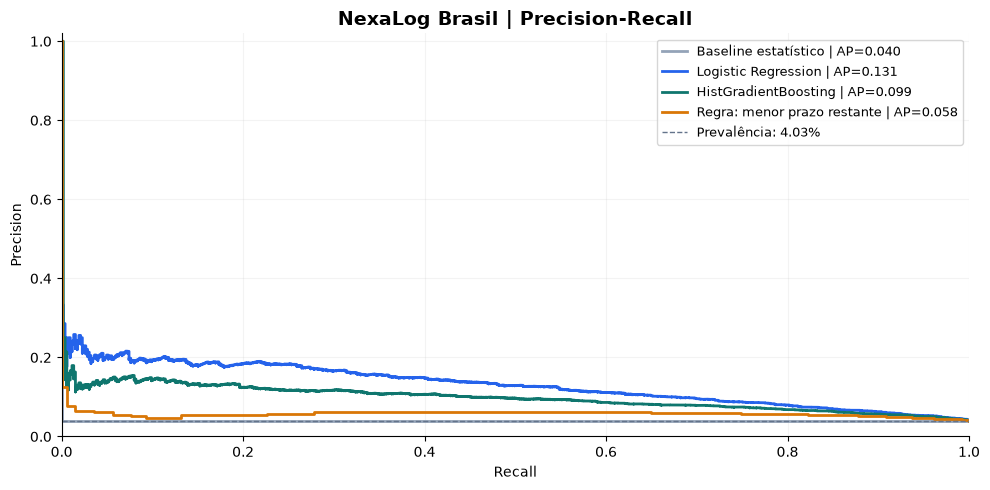


RELATÓRIO 3 — CAPACIDADE OPERACIONAL


,modelo,pedidos_priorizados,atrasos_identificados,lift_at_10,precision_pct,recall_pct,atrasos_esperados_ao_acaso,ganho_sobre_acaso
0,Logistic Regression,1304,194,3.69,14.88,36.95,52.52,141.48
1,HistGradientBoosting,1304,150,2.86,11.50,28.57,52.52,97.48
2,Regra: menor prazo restante,1304,60,1.14,4.60,11.43,52.52,7.48
3,Baseline estatístico,1304,54,1.03,4.14,10.29,52.52,1.48


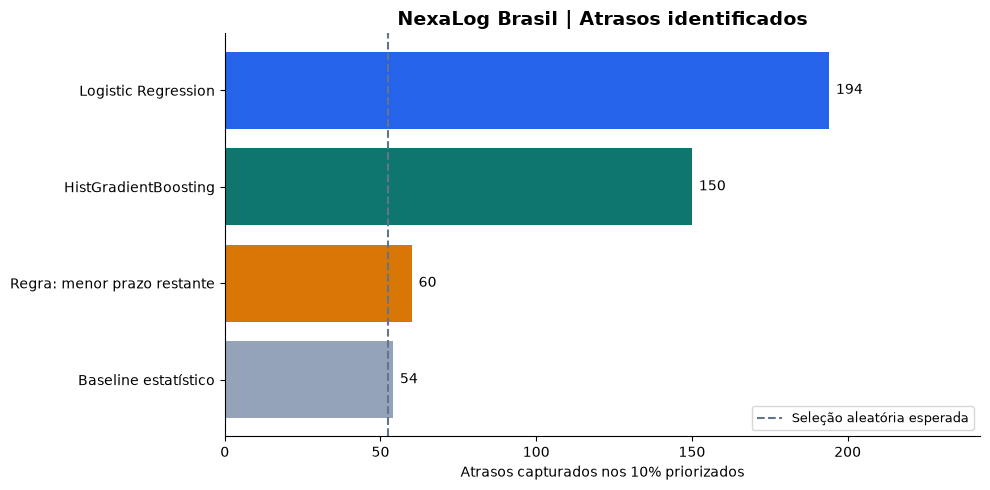


RELATÓRIO 4 — CRITÉRIOS DE VIABILIDADE


,modelo,ap_ok,roc_auc_ok,lift_ok,recall_ok,supera_regra_ap,supera_regra_lift,criterios_atendidos,aprovado
0,Logistic Regression,True,True,True,True,True,True,6,True
1,HistGradientBoosting,True,True,True,True,True,True,6,True



RELATÓRIO 5 — PARECER PRELIMINAR

Modelo candidato: Logistic Regression


,indicador,meta,resultado,status
0,Average Precision,0.0604,0.1311,OK
1,ROC-AUC,0.7000,0.7776,OK
2,Lift@10%,2.0000,3.6935,OK
3,Recall@10%,0.2000,0.3695,OK
4,AP superior à regra,0.0579,0.1311,OK
5,Lift superior à regra,1.1423,3.6935,OK



RESULTADO DA VIABILIDADE PREDITIVA
Pedidos de treinamento: 68,277
Pedidos de validação: 13,034
Pedidos de teste reservados: 12,516
Prevalência na validação: 4.03%
Modelo candidato: Logistic Regression
Average Precision: 0.1311
ROC-AUC: 0.7776
Precision@10%: 14.88%
Recall@10%: 36.95%
Lift@10%: 3.69x
Critérios atendidos: 6/6
Conjunto de teste utilizado: NÃO

VIABILIDADE PRELIMINAR: APROVADA
Prosseguir para decisão Go / No-Go.


In [5]:

# ============================================================
# SPRINT 0 — AULA 05
# Predictive Feasibility & Baseline
# ============================================================

import gc
import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)

from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import (
    HistGradientBoostingClassifier,
)

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
    precision_recall_curve,
)


# ------------------------------------------------------------
# 1. Pré-requisitos e configuração
# ------------------------------------------------------------

assert "feature_base" in globals(), (
    "Execute a célula de código da Aula 04."
)

assert feature_approved, (
    "A base preditiva precisa estar aprovada."
)

RANDOM_STATE = 42
TOP_K = 0.10

VALIDATION_START = pd.Timestamp("2018-05-01")
TEST_START = pd.Timestamp("2018-07-01")
TEST_END = pd.Timestamp("2018-09-01")

print("=" * 75)
print("NEXALOG BRASIL | PREDICTIVE FEASIBILITY")
print("=" * 75)


# ------------------------------------------------------------
# 2. Organização cronológica
# ------------------------------------------------------------

experiment_base = (
    feature_base
    .sort_values([
        "prediction_timestamp",
        "order_id",
    ])
    .reset_index(drop=True)
)

prediction_time = experiment_base[
    "prediction_timestamp"
]

label_time = experiment_base[
    "label_available_at"
]


# ------------------------------------------------------------
# 3. Divisão temporal
# ------------------------------------------------------------

# Treinamento: pedidos aprovados antes da validação.
train_period_mask = (
    prediction_time < VALIDATION_START
)

# Somente resultados conhecidos naquela data.
train_mask = (
    train_period_mask
    & (label_time < VALIDATION_START)
)

validation_mask = (
    (prediction_time >= VALIDATION_START)
    & (prediction_time < TEST_START)
)

test_mask = (
    (prediction_time >= TEST_START)
    & (prediction_time < TEST_END)
)

train_df = experiment_base.loc[
    train_mask
].copy()

validation_df = experiment_base.loc[
    validation_mask
].copy()

test_reserved = experiment_base.loc[
    test_mask
].copy()

purged_train_count = int(
    (train_period_mask & ~train_mask).sum()
)

outside_period_count = int(
    (prediction_time >= TEST_END).sum()
)

assert len(train_df) > 0
assert len(validation_df) > 0
assert len(test_reserved) > 0

assert (
    train_df["label_available_at"].max()
    < VALIDATION_START
)

assert (
    train_df["prediction_timestamp"].max()
    < validation_df["prediction_timestamp"].min()
)

assert (
    validation_df["prediction_timestamp"].max()
    < test_reserved["prediction_timestamp"].min()
)

assert (
    len(train_df)
    + len(validation_df)
    + len(test_reserved)
    + purged_train_count
    + outside_period_count
    == len(experiment_base)
)


# ------------------------------------------------------------
# 4. Relatório da divisão temporal
# ------------------------------------------------------------

split_results = []

for name, dataframe in {
    "Treinamento": train_df,
    "Validação": validation_df,
    "Teste reservado": test_reserved,
}.items():

    result = {
        "conjunto": name,
        "pedidos": len(dataframe),
        "inicio": dataframe[
            "prediction_timestamp"
        ].min(),
        "fim": dataframe[
            "prediction_timestamp"
        ].max(),
    }

    # Não inspecionar a distribuição do alvo
    # do conjunto de teste reservado.
    if name != "Teste reservado":

        result["atrasados"] = int(
            dataframe[TARGET_COLUMN].sum()
        )

        result["taxa_atraso_pct"] = round(
            dataframe[TARGET_COLUMN].mean()
            * 100,
            2,
        )

    else:

        result["atrasados"] = None
        result["taxa_atraso_pct"] = None

    split_results.append(result)

df_temporal_split = pd.DataFrame(
    split_results
)

print("\n" + "=" * 75)
print("RELATÓRIO 1 — DIVISÃO TEMPORAL")
print("=" * 75)

display(df_temporal_split)

print(
    f"\nPedidos removidos do treinamento "
    f"por indisponibilidade do alvo: "
    f"{purged_train_count:,}"
)

print(
    f"Pedidos fora do período experimental: "
    f"{outside_period_count:,}"
)

print(
    "Último resultado conhecido no treino:",
    train_df["label_available_at"].max(),
)

print(
    "Último resultado da validação:",
    validation_df["label_available_at"].max(),
)

validation_labels_after_test_start = int(
    validation_df["label_available_at"]
    .ge(TEST_START)
    .sum()
)

print(
    "Resultados da validação conhecidos "
    "após ou no início do teste:",
    validation_labels_after_test_start,
)


# ------------------------------------------------------------
# 5. Separação das preditoras e do alvo
# ------------------------------------------------------------

def prepare_features(dataframe):

    X = dataframe[FEATURE_COLUMNS].copy()

    # Normalização dos tipos numéricos.
    for column in NUMERIC_FEATURES:

        X[column] = pd.to_numeric(
            X[column],
            errors="coerce",
        ).astype("float64")

    # Compatibilidade dos valores ausentes
    # com os transformadores do Scikit-learn.
    for column in CATEGORICAL_FEATURES:

        values = X[column].astype(object)

        X[column] = values.where(
            pd.notna(values),
            np.nan,
        )

    return X


X_train = prepare_features(train_df)
X_val = prepare_features(validation_df)

y_train = train_df[TARGET_COLUMN].astype(int)
y_val = validation_df[TARGET_COLUMN].astype(int)

assert set(y_train.unique()) == {0, 1}
assert set(y_val.unique()) == {0, 1}

assert list(X_train.columns) == FEATURE_COLUMNS
assert list(X_val.columns) == FEATURE_COLUMNS

assert not (
    set(X_train.columns)
    & FORBIDDEN_FEATURES
)

validation_prevalence = float(y_val.mean())

print(
    f"\nPrevalência na validação: "
    f"{validation_prevalence:.2%}"
)


# ------------------------------------------------------------
# 6. Pré-processamento — Logistic Regression
# ------------------------------------------------------------

linear_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median"),
    ),
    (
        "scaler",
        StandardScaler(),
    ),
])

linear_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="desconhecido",
        ),
    ),
    (
        "encoder",
        OneHotEncoder(
            handle_unknown="ignore",
            sparse_output=True,
        ),
    ),
])

linear_preprocessor = ColumnTransformer([
    (
        "numeric",
        linear_numeric_pipeline,
        NUMERIC_FEATURES,
    ),
    (
        "categorical",
        linear_categorical_pipeline,
        CATEGORICAL_FEATURES,
    ),
])


# ------------------------------------------------------------
# 7. Pré-processamento — HistGradientBoosting
# ------------------------------------------------------------

tree_numeric_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(strategy="median"),
    ),
])

tree_categorical_pipeline = Pipeline([
    (
        "imputer",
        SimpleImputer(
            strategy="constant",
            fill_value="desconhecido",
        ),
    ),
    (
        "encoder",
        OrdinalEncoder(
            handle_unknown="use_encoded_value",
            unknown_value=-1,
        ),
    ),
])

tree_preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            tree_numeric_pipeline,
            NUMERIC_FEATURES,
        ),
        (
            "categorical",
            tree_categorical_pipeline,
            CATEGORICAL_FEATURES,
        ),
    ],
    sparse_threshold=0,
)

# Indicar explicitamente quais colunas são
# categóricas após a transformação.
categorical_mask = (
    [False] * len(NUMERIC_FEATURES)
    + [True] * len(CATEGORICAL_FEATURES)
)


# ------------------------------------------------------------
# 8. Definição dos modelos
# ------------------------------------------------------------

dummy_model = DummyClassifier(
    strategy="prior",
)

logistic_model = Pipeline([
    (
        "preprocessor",
        linear_preprocessor,
    ),
    (
        "classifier",
        LogisticRegression(
            max_iter=1000,
            random_state=RANDOM_STATE,
        ),
    ),
])

boosting_model = Pipeline([
    (
        "preprocessor",
        tree_preprocessor,
    ),
    (
        "classifier",
        HistGradientBoostingClassifier(
            learning_rate=0.08,
            max_iter=150,
            max_leaf_nodes=31,
            min_samples_leaf=30,
            l2_regularization=1.0,
            categorical_features=categorical_mask,
            early_stopping=False,
            random_state=RANDOM_STATE,
        ),
    ),
])

models = {
    "Baseline estatístico": dummy_model,
    "Logistic Regression": logistic_model,
    "HistGradientBoosting": boosting_model,
}


# ------------------------------------------------------------
# 9. Função de avaliação empresarial
# ------------------------------------------------------------

def evaluate_ranking(
    model_name,
    y_true,
    scores,
    top_k=0.10,
    training_seconds=0.0,
):

    y_array = np.asarray(
        y_true,
        dtype=int,
    )

    scores = np.asarray(
        scores,
        dtype=float,
    )

    assert len(y_array) == len(scores)
    assert np.isfinite(scores).all()

    prevalence = y_array.mean()

    total_orders = len(y_array)
    total_late = int(y_array.sum())

    k = max(
        1,
        int(np.ceil(total_orders * top_k)),
    )

    # Desempate reproduzível, independente do alvo.
    rng = np.random.default_rng(RANDOM_STATE)

    tie_breaker = rng.random(total_orders)

    ranked_indices = np.lexsort(
        (tie_breaker, -scores)
    )

    selected_indices = ranked_indices[:k]

    detected_late = int(
        y_array[selected_indices].sum()
    )

    precision_k = detected_late / k

    recall_k = (
        detected_late / total_late
        if total_late else 0.0
    )

    lift_k = (
        precision_k / prevalence
        if prevalence else 0.0
    )

    return {
        "modelo": model_name,
        "average_precision": (
            average_precision_score(
                y_array,
                scores,
            )
        ),
        "roc_auc": roc_auc_score(
            y_array,
            scores,
        ),
        "precision_at_10": precision_k,
        "recall_at_10": recall_k,
        "lift_at_10": lift_k,
        "pedidos_priorizados": k,
        "atrasos_identificados": detected_late,
        "tempo_treino_seg": training_seconds,
    }


# ------------------------------------------------------------
# 10. Treinamento e avaliação
# ------------------------------------------------------------

model_results = []
validation_scores = {}
trained_models = {}

print("\n" + "=" * 75)
print("TREINAMENTO DOS MODELOS")
print("=" * 75)

for model_name, model in models.items():

    print(f"\nTreinando: {model_name}")

    start_time = time.perf_counter()

    model.fit(X_train, y_train)

    elapsed = (
        time.perf_counter() - start_time
    )

    scores = model.predict_proba(X_val)[:, 1]

    validation_scores[model_name] = scores
    trained_models[model_name] = model

    result = evaluate_ranking(
        model_name=model_name,
        y_true=y_val,
        scores=scores,
        top_k=TOP_K,
        training_seconds=elapsed,
    )

    model_results.append(result)

    print(f"Tempo: {elapsed:.2f} segundos")

    print(
        f"Average Precision: "
        f"{result['average_precision']:.4f}"
    )

    print(
        f"ROC-AUC: "
        f"{result['roc_auc']:.4f}"
    )

    print(
        f"Lift@10%: "
        f"{result['lift_at_10']:.2f}x"
    )

    gc.collect()


# ------------------------------------------------------------
# 11. Regra logística de referência
# ------------------------------------------------------------

# Menor prazo restante recebe maior prioridade.
# Trata-se de um score de ordenação,
# não de uma probabilidade de atraso.

rule_name = "Regra: menor prazo restante"

rule_scores = (
    -X_val["remaining_days"]
    .to_numpy(dtype=float)
)

validation_scores[rule_name] = rule_scores

rule_result = evaluate_ranking(
    model_name=rule_name,
    y_true=y_val,
    scores=rule_scores,
    top_k=TOP_K,
)

model_results.append(rule_result)


# ------------------------------------------------------------
# 12. Comparação consolidada
# ------------------------------------------------------------

df_model_results = (
    pd.DataFrame(model_results)
    .sort_values(
        "average_precision",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("\n" + "=" * 75)
print("RELATÓRIO 2 — COMPARAÇÃO DOS MODELOS")
print("=" * 75)

display(
    df_model_results.round(4)
)


# ------------------------------------------------------------
# 13. Curvas Precision-Recall
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 5))

plot_colors = {
    "Baseline estatístico": "#94A3B8",
    "Regra: menor prazo restante": "#D97706",
    "Logistic Regression": "#2563EB",
    "HistGradientBoosting": "#0F766E",
}

for model_name, scores in (
    validation_scores.items()
):

    precision, recall, _ = (
        precision_recall_curve(
            y_val,
            scores,
        )
    )

    ap = average_precision_score(
        y_val,
        scores,
    )

    ax.step(
        recall,
        precision,
        where="post",
        linewidth=2,
        color=plot_colors[model_name],
        label=f"{model_name} | AP={ap:.3f}",
    )

ax.axhline(
    validation_prevalence,
    color="#64748B",
    linestyle="--",
    linewidth=1,
    label=(
        f"Prevalência: "
        f"{validation_prevalence:.2%}"
    ),
)

ax.set_title(
    "NexaLog Brasil | Precision-Recall",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel("Recall")
ax.set_ylabel("Precision")

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)

ax.grid(alpha=0.15)
ax.legend(fontsize=9)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Comparação da capacidade operacional
# ------------------------------------------------------------

df_operational = df_model_results[[
    "modelo",
    "pedidos_priorizados",
    "atrasos_identificados",
    "precision_at_10",
    "recall_at_10",
    "lift_at_10",
]].copy()

df_operational["precision_pct"] = (
    df_operational["precision_at_10"] * 100
).round(2)

df_operational["recall_pct"] = (
    df_operational["recall_at_10"] * 100
).round(2)

df_operational["atrasos_esperados_ao_acaso"] = (
    df_operational["pedidos_priorizados"]
    * validation_prevalence
).round(2)

df_operational["ganho_sobre_acaso"] = (
    df_operational["atrasos_identificados"]
    - df_operational[
        "atrasos_esperados_ao_acaso"
    ]
).round(2)

df_operational = df_operational.drop(
    columns=[
        "precision_at_10",
        "recall_at_10",
    ]
)

print("\n" + "=" * 75)
print("RELATÓRIO 3 — CAPACIDADE OPERACIONAL")
print("=" * 75)

display(df_operational.round(2))


# ------------------------------------------------------------
# 15. Gráfico de atrasos identificados
# ------------------------------------------------------------

plot_data = df_operational.sort_values(
    "atrasos_identificados",
    ascending=True,
)

fig, ax = plt.subplots(figsize=(10, 5))

bars = ax.barh(
    plot_data["modelo"],
    plot_data["atrasos_identificados"],
    color=[
        plot_colors[name]
        for name in plot_data["modelo"]
    ],
)

random_expected = float(
    df_operational[
        "atrasos_esperados_ao_acaso"
    ].iloc[0]
)

ax.axvline(
    random_expected,
    color="#64748B",
    linestyle="--",
    label="Seleção aleatória esperada",
)

ax.bar_label(
    bars,
    padding=5,
    fontsize=10,
)

ax.set_title(
    "NexaLog Brasil | Atrasos identificados",
    fontsize=14,
    fontweight="bold",
)

ax.set_xlabel(
    "Atrasos capturados nos 10% priorizados"
)

ax.set_xlim(
    0,
    max(
        plot_data["atrasos_identificados"].max(),
        random_expected,
        1,
    ) * 1.25,
)

ax.legend(fontsize=9)

ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 16. Avaliação dos critérios de viabilidade
# ------------------------------------------------------------

minimum_ap = (
    validation_prevalence * 1.5
)

minimum_roc_auc = 0.70
minimum_lift = 2.0
minimum_recall = 0.20

candidate_names = [
    "Logistic Regression",
    "HistGradientBoosting",
]

candidate_results = df_model_results.loc[
    df_model_results["modelo"].isin(
        candidate_names
    )
].copy()

candidate_results["ap_ok"] = (
    candidate_results["average_precision"]
    >= minimum_ap
)

candidate_results["roc_auc_ok"] = (
    candidate_results["roc_auc"]
    >= minimum_roc_auc
)

candidate_results["lift_ok"] = (
    candidate_results["lift_at_10"]
    >= minimum_lift
)

candidate_results["recall_ok"] = (
    candidate_results["recall_at_10"]
    >= minimum_recall
)

candidate_results["supera_regra_ap"] = (
    candidate_results["average_precision"]
    > rule_result["average_precision"]
)

candidate_results["supera_regra_lift"] = (
    candidate_results["lift_at_10"]
    > rule_result["lift_at_10"]
)

criteria_columns = [
    "ap_ok",
    "roc_auc_ok",
    "lift_ok",
    "recall_ok",
    "supera_regra_ap",
    "supera_regra_lift",
]

candidate_results["criterios_atendidos"] = (
    candidate_results[criteria_columns]
    .sum(axis=1)
)

candidate_results["aprovado"] = (
    candidate_results[criteria_columns]
    .all(axis=1)
)

print("\n" + "=" * 75)
print("RELATÓRIO 4 — CRITÉRIOS DE VIABILIDADE")
print("=" * 75)

display(
    candidate_results[
        ["modelo"]
        + criteria_columns
        + [
            "criterios_atendidos",
            "aprovado",
        ]
    ]
)


# ------------------------------------------------------------
# 17. Seleção preliminar do modelo
# ------------------------------------------------------------

approved_candidates = (
    candidate_results.loc[
        candidate_results["aprovado"]
    ]
    .sort_values(
        [
            "lift_at_10",
            "average_precision",
        ],
        ascending=False,
    )
)

feasibility_approved = (
    not approved_candidates.empty
)

if feasibility_approved:

    selected_result = (
        approved_candidates.iloc[0]
    )

else:

    # Melhor candidato para diagnóstico,
    # sem aprovação automática.
    selected_result = (
        candidate_results
        .sort_values(
            [
                "criterios_atendidos",
                "lift_at_10",
                "average_precision",
            ],
            ascending=False,
        )
        .iloc[0]
    )

best_model_name = selected_result["modelo"]

df_feasibility = pd.DataFrame([
    {
        "indicador": "Average Precision",
        "meta": minimum_ap,
        "resultado": selected_result[
            "average_precision"
        ],
        "status": selected_result["ap_ok"],
    },
    {
        "indicador": "ROC-AUC",
        "meta": minimum_roc_auc,
        "resultado": selected_result[
            "roc_auc"
        ],
        "status": selected_result["roc_auc_ok"],
    },
    {
        "indicador": "Lift@10%",
        "meta": minimum_lift,
        "resultado": selected_result[
            "lift_at_10"
        ],
        "status": selected_result["lift_ok"],
    },
    {
        "indicador": "Recall@10%",
        "meta": minimum_recall,
        "resultado": selected_result[
            "recall_at_10"
        ],
        "status": selected_result["recall_ok"],
    },
    {
        "indicador": "AP superior à regra",
        "meta": rule_result[
            "average_precision"
        ],
        "resultado": selected_result[
            "average_precision"
        ],
        "status": selected_result[
            "supera_regra_ap"
        ],
    },
    {
        "indicador": "Lift superior à regra",
        "meta": rule_result["lift_at_10"],
        "resultado": selected_result[
            "lift_at_10"
        ],
        "status": selected_result[
            "supera_regra_lift"
        ],
    },
])

df_feasibility["status"] = (
    df_feasibility["status"].map({
        True: "OK",
        False: "REVISAR",
    })
)

print("\n" + "=" * 75)
print("RELATÓRIO 5 — PARECER PRELIMINAR")
print("=" * 75)

print(f"\nModelo candidato: {best_model_name}")

display(df_feasibility.round(4))


# ------------------------------------------------------------
# 18. Resultado final da aula
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("RESULTADO DA VIABILIDADE PREDITIVA")
print("=" * 75)

print(
    f"Pedidos de treinamento: "
    f"{len(train_df):,}"
)

print(
    f"Pedidos de validação: "
    f"{len(validation_df):,}"
)

print(
    f"Pedidos de teste reservados: "
    f"{len(test_reserved):,}"
)

print(
    f"Prevalência na validação: "
    f"{validation_prevalence:.2%}"
)

print(f"Modelo candidato: {best_model_name}")

print(
    f"Average Precision: "
    f"{selected_result['average_precision']:.4f}"
)

print(
    f"ROC-AUC: "
    f"{selected_result['roc_auc']:.4f}"
)

print(
    f"Precision@10%: "
    f"{selected_result['precision_at_10']:.2%}"
)

print(
    f"Recall@10%: "
    f"{selected_result['recall_at_10']:.2%}"
)

print(
    f"Lift@10%: "
    f"{selected_result['lift_at_10']:.2f}x"
)

print(
    f"Critérios atendidos: "
    f"{selected_result['criterios_atendidos']}"
    f"/{len(criteria_columns)}"
)

print("Conjunto de teste utilizado: NÃO")

print("\n" + "=" * 75)

if feasibility_approved:

    print("VIABILIDADE PRELIMINAR: APROVADA")
    print("Prosseguir para decisão Go / No-Go.")

else:

    print("VIABILIDADE PRELIMINAR: NÃO COMPROVADA")
    print("Investigar os critérios não atendidos.")

print("=" * 75)



---

### 0.6 — Go / No-Go Decision

#### Objetivo

Avaliar a viabilidade técnica e empresarial
do sistema de priorização de atrasos.

#### Evidências preliminares

- Modelo candidato: Logistic Regression.
- ROC-AUC: 0.7776.
- Average Precision: 0.1311.
- Lift@10%: 3.69.
- Recall@10%: 36.95%.
- Critérios preliminares: 6/6.

#### Pendência metodológica

Verificar a disponibilidade temporal dos
rótulos utilizados na seleção do modelo.

A validação retrospectiva foi satisfatória,
mas parte de seus resultados somente ficou
conhecida durante o período reservado
para teste.

#### Decisão

GO condicionado à correção e aprovação
do protocolo temporal definitivo.

Não utilizar o conjunto de teste para
selecionar modelos ou ajustar parâmetros.


In [6]:

# ============================================================
# NEXALOG BRASIL | SPRINT 0 — AULA 06
# Auditoria final do protocolo temporal
# ============================================================

import pandas as pd
from IPython.display import display

assert "experiment_base" in globals()
assert "df_model_results" in globals()
assert "feasibility_approved" in globals()

# Cortes do experimento executado
validation_start = pd.Timestamp("2018-05-01")
test_start = pd.Timestamp("2018-07-01")

# Proposta alternativa:
# validação em março e abril;
# maio e junho para maturação dos resultados;
# teste reservado em julho e agosto.
new_validation_start = pd.Timestamp("2018-03-01")
new_validation_end = pd.Timestamp("2018-05-01")

prediction = experiment_base["prediction_timestamp"]
label = experiment_base["label_available_at"]

original_validation = (
    (prediction >= validation_start)
    & (prediction < test_start)
)

alternative_train = (
    (prediction < new_validation_start)
    & (label < new_validation_start)
)

alternative_validation = (
    (prediction >= new_validation_start)
    & (prediction < new_validation_end)
)

alternative_known_labels = (
    alternative_validation
    & (label < test_start)
)

alternative_unavailable = (
    alternative_validation
    & (label >= test_start)
)

report = pd.DataFrame([
    {
        "indicador": "Validação original",
        "pedidos": int(original_validation.sum())
    },
    {
        "indicador": "Rótulos originais indisponíveis em 01/07",
        "pedidos": int(
            (original_validation & (label >= test_start)).sum()
        )
    },
    {
        "indicador": "Treinamento alternativo",
        "pedidos": int(alternative_train.sum())
    },
    {
        "indicador": "Validação alternativa",
        "pedidos": int(alternative_validation.sum())
    },
    {
        "indicador": "Rótulos conhecidos até 01/07",
        "pedidos": int(alternative_known_labels.sum())
    },
    {
        "indicador": "Rótulos ainda indisponíveis em 01/07",
        "pedidos": int(alternative_unavailable.sum())
    },
])

print("=" * 70)
print("RELATÓRIO 1 — AUDITORIA TEMPORAL FINAL")
print("=" * 70)
display(report)

# Apenas diagnóstico de composição da validação
# alternativa. Nenhum resultado do teste é acessado.
validation_diagnostic = (
    experiment_base.loc[
        alternative_validation,
        ["is_late", "label_available_at"]
    ]
    .assign(
        conhecido_ate_corte=lambda d:
            d["label_available_at"] < test_start
    )
    .groupby("conhecido_ate_corte")
    .agg(
        pedidos=("is_late", "size"),
        atrasados=("is_late", "sum")
    )
    .reset_index()
)

validation_diagnostic["taxa_atraso_pct"] = (
    100
    * validation_diagnostic["atrasados"]
    / validation_diagnostic["pedidos"]
)

print("\nRELATÓRIO 2 — MATURAÇÃO DOS RÓTULOS")
display(validation_diagnostic.round(2))

print("\nRELATÓRIO 3 — PARECER")
print("Viabilidade preditiva preliminar:",
      "APROVADA" if feasibility_approved else "REVISAR")

print("Protocolo temporal definitivo: PENDENTE")
print("Teste reservado: NÃO UTILIZADO")
print(
    "Próxima decisão: definir um protocolo sem "
    "vazamento temporal e sem viés relevante "
    "pela exclusão de entregas ainda não observadas."
)


RELATÓRIO 1 — AUDITORIA TEMPORAL FINAL


,indicador,pedidos
0,Validação original,13034
1,Rótulos originais indisponíveis em 01/07,1653
2,Treinamento alternativo,53618
3,Validação alternativa,13707
4,Rótulos conhecidos até 01/07,13703
5,Rótulos ainda indisponíveis em 01/07,4



RELATÓRIO 2 — MATURAÇÃO DOS RÓTULOS


,conhecido_ate_corte,pedidos,atrasados,taxa_atraso_pct
0,False,4,4,100.00
1,True,13703,1662,12.13



RELATÓRIO 3 — PARECER
Viabilidade preditiva preliminar: APROVADA
Protocolo temporal definitivo: PENDENTE
Teste reservado: NÃO UTILIZADO
Próxima decisão: definir um protocolo sem vazamento temporal e sem viés relevante pela exclusão de entregas ainda não observadas.



---

### 0.6.1 — Validação temporal definitiva

#### Objetivo

Confirmar a viabilidade preditiva utilizando
o calendário alternativo.

#### Protocolo

- Treinamento: aprovações anteriores a março/2018.
- Rótulos do treino: conhecidos antes de março/2018.
- Validação: aprovações de março e abril/2018.
- Corte de disponibilidade: 01/07/2018.
- Teste reservado: julho e agosto/2018.

#### Estratégia

Treinar novamente a Logistic Regression e
compará-la com o baseline estatístico e a
regra logística.

Utilizar somente rótulos disponíveis até
01/07/2018 para a seleção do modelo.

Realizar análise de sensibilidade com os
quatro rótulos tardios, sem utilizá-la para
selecionar o modelo.

#### Critérios

Manter as seis metas de viabilidade
definidas na Aula 05.

#### Restrição

Não acessar os resultados do teste reservado.

#### Decisão

A aprovação dependerá do desempenho real
no novo período de validação.


In [7]:

# ============================================================
# NEXALOG BRASIL | SPRINT 0 — AULA 06
# Confirmação da viabilidade temporal
# ============================================================

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from IPython.display import display

# 1. Pré-requisitos
required_objects = [
    "experiment_base",
    "alternative_train",
    "alternative_validation",
    "alternative_known_labels",
    "logistic_model",
    "prepare_features",
    "evaluate_ranking",
    "FEATURE_COLUMNS",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Pré-requisitos ausentes: {missing_objects}"
)

print("=" * 70)
print("NEXALOG BRASIL | FINAL TEMPORAL VALIDATION")
print("=" * 70)

# 2. Construção dos conjuntos
train_final = experiment_base.loc[
    alternative_train
].copy()

val_final = experiment_base.loc[
    alternative_known_labels
].copy()

# Apenas para análise de sensibilidade retrospectiva.
val_full = experiment_base.loc[
    alternative_validation
].copy()

X_train_final = prepare_features(train_final)
y_train_final = train_final["is_late"].astype(int)

X_val_final = prepare_features(val_final)
y_val_final = val_final["is_late"].astype(int)

assert len(train_final) == 53618
assert len(val_final) == 13703

assert train_final["label_available_at"].max() < (
    pd.Timestamp("2018-03-01")
)

assert val_final["label_available_at"].max() < (
    pd.Timestamp("2018-07-01")
)

assert set(y_train_final.unique()) == {0, 1}
assert set(y_val_final.unique()) == {0, 1}

# 3. Modelos sem reaproveitar parâmetros ajustados
models_final = {
    "Baseline estatístico": DummyClassifier(
        strategy="prior"
    ),
    "Logistic Regression": clone(logistic_model),
}

results_final = {}
fitted_final = {}

for name, model in models_final.items():

    print(f"\nTreinando: {name}")

    model.fit(X_train_final, y_train_final)

    scores = model.predict_proba(
        X_val_final
    )[:, 1]

    results_final[name] = evaluate_ranking(
        name,
        y_val_final,
        scores,
        top_k=0.10,
    )

    fitted_final[name] = model

# 4. Regra logística
rule_scores = (
    -X_val_final["remaining_days"]
    .to_numpy(dtype=float)
)

results_final["Regra logística"] = evaluate_ranking(
    "Regra logística",
    y_val_final,
    rule_scores,
    top_k=0.10,
)

# 5. Comparação
df_final_comparison = (
    pd.DataFrame(results_final.values())
    .sort_values(
        "average_precision",
        ascending=False,
    )
    .reset_index(drop=True)
)

print("\nRELATÓRIO 1 — COMPARAÇÃO TEMPORAL")
display(df_final_comparison.round(4))

# 6. Critérios de aprovação
candidate = results_final["Logistic Regression"]
rule = results_final["Regra logística"]

prevalence = float(y_val_final.mean())

checks = {
    "AP >= 1,5x prevalência":
        candidate["average_precision"] >= prevalence * 1.5,

    "ROC-AUC >= 0,70":
        candidate["roc_auc"] >= 0.70,

    "Lift@10% >= 2,0":
        candidate["lift_at_10"] >= 2.0,

    "Recall@10% >= 20%":
        candidate["recall_at_10"] >= 0.20,

    "AP superior à regra":
        candidate["average_precision"]
        > rule["average_precision"],

    "Lift superior à regra":
        candidate["lift_at_10"]
        > rule["lift_at_10"],
}

df_final_checks = pd.DataFrame([
    {
        "criterio": name,
        "status": "OK" if passed else "REVISAR",
    }
    for name, passed in checks.items()
])

print("\nRELATÓRIO 2 — CRITÉRIOS DE ACEITAÇÃO")
display(df_final_checks)

# 7. Análise de sensibilidade retrospectiva
# Não participa da seleção do modelo.
X_val_full = prepare_features(val_full)
y_val_full = val_full["is_late"].astype(int)

full_scores = fitted_final[
    "Logistic Regression"
].predict_proba(X_val_full)[:, 1]

sensitivity = evaluate_ranking(
    "Logistic Regression — retrospectiva",
    y_val_full,
    full_scores,
    top_k=0.10,
)

df_sensitivity = pd.DataFrame([
    {
        "amostra": "Rótulos disponíveis até 01/07",
        "pedidos": len(val_final),
        "atrasados": int(y_val_final.sum()),
        "ap": candidate["average_precision"],
        "lift": candidate["lift_at_10"],
        "recall": candidate["recall_at_10"],
    },
    {
        "amostra": "Validação completa retrospectiva",
        "pedidos": len(val_full),
        "atrasados": int(y_val_full.sum()),
        "ap": sensitivity["average_precision"],
        "lift": sensitivity["lift_at_10"],
        "recall": sensitivity["recall_at_10"],
    },
])

print("\nRELATÓRIO 3 — SENSIBILIDADE")
display(df_sensitivity.round(4))

# 8. Parecer
temporal_feasibility_approved = all(checks.values())

print("\n" + "=" * 70)
print("PARECER FINAL — VIABILIDADE TEMPORAL")
print("=" * 70)

print(f"Treinamento: {len(train_final):,}")
print(f"Validação disponível: {len(val_final):,}")
print(f"Prevalência: {prevalence:.2%}")
print(f"Critérios atendidos: {sum(checks.values())}/6")
print("Teste reservado utilizado: NÃO")

if temporal_feasibility_approved:
    print("\nVIABILIDADE TEMPORAL: APROVADA")
    print("Elegível para decisão GO.")
else:
    print("\nVIABILIDADE TEMPORAL: NÃO APROVADA")
    print("Revisão empresarial necessária.")

print("=" * 70)


NEXALOG BRASIL | FINAL TEMPORAL VALIDATION

Treinando: Baseline estatístico

Treinando: Logistic Regression

RELATÓRIO 1 — COMPARAÇÃO TEMPORAL


,modelo,average_precision,roc_auc,precision_at_10,recall_at_10,lift_at_10,pedidos_priorizados,atrasos_identificados,tempo_treino_seg
0,Logistic Regression,0.2380,0.6812,0.3136,0.2587,2.5859,1371,430,0.0
1,Baseline estatístico,0.1213,0.5000,0.1320,0.1089,1.0885,1371,181,0.0
2,Regra logística,0.1118,0.4884,0.0438,0.0361,0.3608,1371,60,0.0



RELATÓRIO 2 — CRITÉRIOS DE ACEITAÇÃO


,criterio,status
0,"AP >= 1,5x prevalência",OK
1,"ROC-AUC >= 0,70",REVISAR
2,"Lift@10% >= 2,0",OK
3,Recall@10% >= 20%,OK
4,AP superior à regra,OK
5,Lift superior à regra,OK



RELATÓRIO 3 — SENSIBILIDADE


,amostra,pedidos,atrasados,ap,lift,recall
0,Rótulos disponíveis até 01/07,13703,1662,0.2380,2.5859,0.2587
1,Validação completa retrospectiva,13707,1666,0.2387,2.5865,0.2587



PARECER FINAL — VIABILIDADE TEMPORAL
Treinamento: 53,618
Validação disponível: 13,703
Prevalência: 12.13%
Critérios atendidos: 5/6
Teste reservado utilizado: NÃO

VIABILIDADE TEMPORAL: NÃO APROVADA
Revisão empresarial necessária.



---

### 0.6.2 — Temporal Stability Diagnostic

#### Objetivo empresarial

Investigar a estabilidade temporal da
Logistic Regression e identificar possíveis
mudanças no comportamento dos atrasos.

#### Perguntas de investigação

1. A prevalência de atrasos varia entre os meses?
2. O modelo apresenta desempenho consistente?
3. Existem indícios de mudança na distribuição?

#### Metodologia

- Utilizar exclusivamente dados de treinamento
  e validação já autorizados.
- Não realizar novo treinamento.
- Não modificar os hiperparâmetros.
- Não utilizar o conjunto de teste reservado.
- Calcular métricas mensais de desempenho.
- Comparar distribuições de preditoras
  operacionais relevantes.

#### Decisão esperada

Determinar se existe estabilidade suficiente
para justificar a continuidade do projeto
ou se será necessário revisar a estratégia.

A análise é diagnóstica e não substitui
os critérios de aceitação originais.


In [8]:

# ============================================================
# NEXALOG BRASIL | SPRINT 0 — AULA 06
# Temporal Stability Diagnostic
# ============================================================

import numpy as np
import pandas as pd

from IPython.display import display
from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

# ------------------------------------------------------------
# 1. Pré-requisitos
# ------------------------------------------------------------

required = [
    "train_final",
    "val_final",
    "fitted_final",
    "prepare_features",
    "evaluate_ranking",
]

missing = [
    name for name in required
    if name not in globals()
]

assert not missing, (
    f"Objetos ausentes: {missing}"
)

print("=" * 70)
print("NEXALOG BRASIL | TEMPORAL STABILITY DIAGNOSTIC")
print("=" * 70)

# ------------------------------------------------------------
# 2. Distribuição mensal dos pedidos
# ------------------------------------------------------------

historical = pd.concat(
    [
        train_final.assign(
            conjunto="Treinamento"
        ),
        val_final.assign(
            conjunto="Validação"
        ),
    ],
    ignore_index=True,
)

historical["mes"] = (
    historical["prediction_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

monthly = (
    historical
    .groupby(
        ["conjunto", "mes"],
        as_index=False,
    )
    .agg(
        pedidos=("is_late", "size"),
        atrasados=("is_late", "sum"),
    )
)

monthly["taxa_atraso_pct"] = (
    monthly["atrasados"]
    / monthly["pedidos"]
    * 100
).round(2)

print("\nRELATÓRIO 1 — DISTRIBUIÇÃO MENSAL")
display(monthly)

# ------------------------------------------------------------
# 3. Avaliação mensal do modelo
# ------------------------------------------------------------

model = fitted_final["Logistic Regression"]

X_validation = prepare_features(val_final)

validation_scores = model.predict_proba(
    X_validation
)[:, 1]

monthly_validation = val_final[
    [
        "prediction_timestamp",
        "is_late",
    ]
].copy()

monthly_validation["score"] = (
    validation_scores
)

monthly_validation["mes"] = (
    monthly_validation[
        "prediction_timestamp"
    ]
    .dt.to_period("M")
    .astype(str)
)

performance = []

for month, group in monthly_validation.groupby(
    "mes",
    sort=True,
):

    y = group["is_late"].astype(int)
    scores = group["score"].to_numpy()

    if y.nunique() < 2:
        continue

    result = evaluate_ranking(
        model_name="Logistic Regression",
        y_true=y,
        scores=scores,
        top_k=0.10,
    )

    performance.append({
        "mes": month,
        "pedidos": len(group),
        "prevalencia_pct": round(
            y.mean() * 100, 2
        ),
        "average_precision": result[
            "average_precision"
        ],
        "roc_auc": result["roc_auc"],
        "lift_at_10": result["lift_at_10"],
        "recall_at_10": result["recall_at_10"],
    })

df_monthly_performance = pd.DataFrame(
    performance
)

print("\nRELATÓRIO 2 — DESEMPENHO MENSAL")
display(df_monthly_performance.round(4))

# ------------------------------------------------------------
# 4. Comparação de distribuições
# ------------------------------------------------------------

variables = [
    "remaining_days",
    "promised_days",
    "total_price",
    "total_freight",
    "item_count",
]

available_variables = [
    col for col in variables
    if col in train_final.columns
    and col in val_final.columns
]

distribution_results = []

for column in available_variables:

    train_values = pd.to_numeric(
        train_final[column],
        errors="coerce",
    )

    val_values = pd.to_numeric(
        val_final[column],
        errors="coerce",
    )

    train_median = train_values.median()
    val_median = val_values.median()

    distribution_results.append({
        "variavel": column,
        "mediana_treino": train_median,
        "mediana_validacao": val_median,
        "diferenca_absoluta": abs(
            val_median - train_median
        ),
    })

df_distribution = pd.DataFrame(
    distribution_results
)

print("\nRELATÓRIO 3 — DISTRIBUIÇÃO DAS PREDITORAS")
display(df_distribution.round(3))

# ------------------------------------------------------------
# 5. Diagnóstico consolidado
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("PARECER — ESTABILIDADE TEMPORAL")
print("=" * 70)

print(
    "Meses avaliados:",
    len(df_monthly_performance)
)

if not df_monthly_performance.empty:

    print(
        "Menor ROC-AUC mensal:",
        round(
            df_monthly_performance[
                "roc_auc"
            ].min(),
            4,
        )
    )

    print(
        "Maior ROC-AUC mensal:",
        round(
            df_monthly_performance[
                "roc_auc"
            ].max(),
            4,
        )
    )

    print(
        "Menor Lift@10% mensal:",
        round(
            df_monthly_performance[
                "lift_at_10"
            ].min(),
            4,
        )
    )

print("\nTreinamento adicional: NÃO")
print("Teste reservado utilizado: NÃO")
print("Critérios de aprovação alterados: NÃO")

print(
    "\nDecisão: aguardar análise técnica "
    "dos resultados mensais."
)

print("=" * 70)


NEXALOG BRASIL | TEMPORAL STABILITY DIAGNOSTIC

RELATÓRIO 1 — DISTRIBUIÇÃO MENSAL


,conjunto,mes,pedidos,atrasados,taxa_atraso_pct
0,Treinamento,2016-09,1,1,100.00
1,Treinamento,2016-10,265,2,0.75
2,Treinamento,2016-12,1,0,0.00
3,Treinamento,2017-01,715,21,2.94
4,Treinamento,2017-02,1638,46,2.81
5,Treinamento,2017-03,2553,118,4.62
6,Treinamento,2017-04,2278,149,6.54
7,Treinamento,2017-05,3547,108,3.04
8,Treinamento,2017-06,3143,95,3.02
9,Treinamento,2017-07,3827,107,2.80



RELATÓRIO 2 — DESEMPENHO MENSAL


,mes,pedidos,prevalencia_pct,average_precision,roc_auc,lift_at_10,recall_at_10
0,2018-03,7083,19.20,0.3509,0.6801,2.3580,0.2360
1,2018-04,6620,4.56,0.1467,0.7686,3.8411,0.3841



RELATÓRIO 3 — DISTRIBUIÇÃO DAS PREDITORAS


,variavel,mediana_treino,mediana_validacao,diferenca_absoluta
0,remaining_days,24.00,22.00,2.00
1,promised_days,25.00,23.00,2.00
2,total_price,84.99,89.10,4.11
3,total_freight,16.46,18.23,1.77
4,item_count,1.00,1.00,0.00



PARECER — ESTABILIDADE TEMPORAL
Meses avaliados: 2
Menor ROC-AUC mensal: 0.6801
Maior ROC-AUC mensal: 0.7686
Menor Lift@10% mensal: 2.358

Treinamento adicional: NÃO
Teste reservado utilizado: NÃO
Critérios de aprovação alterados: NÃO

Decisão: aguardar análise técnica dos resultados mensais.



---

## Sprint 1 — Engenharia do Pipeline

### Aula 01 — Model Registry & Reproducibility

#### Objetivo

Preparar a Logistic Regression para utilização
em uma aplicação empresarial reproduzível.

#### Requisitos

- Reutilizar o pipeline validado.
- Preservar a definição das 19 preditoras.
- Manter o protocolo temporal.
- Registrar as métricas de validação.
- Garantir a integridade do artefato.
- Não utilizar o conjunto de teste reservado.

#### Entregáveis

1. Pipeline treinado e serializado.
2. Metadados do modelo.
3. Lista de variáveis de entrada.
4. Registro das métricas de validação.
5. Verificação de integridade do artefato.

#### Critério de aceitação

O artefato salvo deverá produzir as mesmas
probabilidades do pipeline em memória.

#### Observação

O modelo permanece candidato até a avaliação
final fora da amostra.


In [9]:

# ============================================================
# NEXALOG BRASIL | SPRINT 1 — AULA 01
# Model Registry & Reproducibility
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import joblib
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Pré-requisitos
# ------------------------------------------------------------

required = [
    "fitted_final",
    "train_final",
    "val_final",
    "prepare_features",
    "FEATURE_COLUMNS",
    "NUMERIC_FEATURES",
    "CATEGORICAL_FEATURES",
    "results_final",
]

missing = [
    name for name in required
    if name not in globals()
]

assert not missing, (
    f"Pré-requisitos ausentes: {missing}"
)

# ------------------------------------------------------------
# 2. Diretórios
# ------------------------------------------------------------

PROJECT_ROOT = Path.cwd()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

MODEL_DIR = PROJECT_ROOT / "models"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

MODEL_PATH = MODEL_DIR / "logistic_pipeline.joblib"
METADATA_PATH = MODEL_DIR / "model_metadata.json"

# ------------------------------------------------------------
# 3. Modelo candidato
# ------------------------------------------------------------

model = fitted_final["Logistic Regression"]

X_validation = prepare_features(val_final)

assert list(X_validation.columns) == list(
    FEATURE_COLUMNS
)

# Amostra determinística para verificar persistência.
X_sample = X_validation.head(100).copy()

probabilities_before = model.predict_proba(
    X_sample
)[:, 1]

assert np.isfinite(probabilities_before).all()

# ------------------------------------------------------------
# 4. Persistência
# ------------------------------------------------------------

joblib.dump(
    model,
    MODEL_PATH,
    compress=3,
)

# ------------------------------------------------------------
# 5. Carregamento e comparação
# ------------------------------------------------------------

loaded_model = joblib.load(MODEL_PATH)

probabilities_after = loaded_model.predict_proba(
    X_sample
)[:, 1]

np.testing.assert_allclose(
    probabilities_before,
    probabilities_after,
    rtol=1e-12,
    atol=1e-12,
)

# ------------------------------------------------------------
# 6. Integridade SHA-256
# ------------------------------------------------------------

def calculate_sha256(path):

    digest = hashlib.sha256()

    with open(path, "rb") as file:
        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


model_sha256 = calculate_sha256(MODEL_PATH)

# ------------------------------------------------------------
# 7. Metadados
# ------------------------------------------------------------

validation_metrics = results_final[
    "Logistic Regression"
]

metadata = {
    "project": "NexaLog Brasil",
    "model_name": "Logistic Regression",
    "model_status": "candidate",
    "created_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "prediction_unit": "order",
    "target": "is_late",
    "prediction_moment": "order_approval",
    "training_records": int(len(train_final)),
    "validation_records": int(len(val_final)),
    "feature_count": len(FEATURE_COLUMNS),
    "features": list(FEATURE_COLUMNS),
    "numeric_features": list(NUMERIC_FEATURES),
    "categorical_features": list(
        CATEGORICAL_FEATURES
    ),
    "training_cutoff": "2018-03-01",
    "validation_start": "2018-03-01",
    "validation_end": "2018-05-01",
    "label_availability_cutoff": "2018-07-01",
    "test_status": "reserved",
    "metrics": {
        "average_precision": float(
            validation_metrics["average_precision"]
        ),
        "roc_auc": float(
            validation_metrics["roc_auc"]
        ),
        "precision_at_10": float(
            validation_metrics["precision_at_10"]
        ),
        "recall_at_10": float(
            validation_metrics["recall_at_10"]
        ),
        "lift_at_10": float(
            validation_metrics["lift_at_10"]
        ),
    },
    "model_sha256": model_sha256,
}

with open(
    METADATA_PATH,
    "w",
    encoding="utf-8",
) as file:

    json.dump(
        metadata,
        file,
        ensure_ascii=False,
        indent=2,
    )

# ------------------------------------------------------------
# 8. Validação final
# ------------------------------------------------------------

assert MODEL_PATH.exists()
assert METADATA_PATH.exists()

assert metadata["feature_count"] == 19

assert metadata["model_sha256"] == (
    calculate_sha256(MODEL_PATH)
)

print("=" * 70)
print("NEXALOG BRASIL | MODEL REGISTRY")
print("=" * 70)

print(f"Modelo: {MODEL_PATH}")
print(f"Metadados: {METADATA_PATH}")

print(f"\nTreinamento: {len(train_final):,}")
print(f"Validação: {len(val_final):,}")

print(
    f"Variáveis preditoras: "
    f"{metadata['feature_count']}"
)

print(
    "\nPersistência:",
    "APROVADA",
)

print(
    "Integridade SHA-256:",
    "APROVADA",
)

print(
    "Reprodutibilidade das probabilidades:",
    "APROVADA",
)

print(
    "Conjunto de teste utilizado:",
    "NÃO",
)

print(
    "Status do modelo:",
    metadata["model_status"],
)

print("=" * 70)


NEXALOG BRASIL | MODEL REGISTRY
Modelo: g:\Desktop\PROJETOS\logistics-intelligence\models\logistic_pipeline.joblib
Metadados: g:\Desktop\PROJETOS\logistics-intelligence\models\model_metadata.json

Treinamento: 53,618
Validação: 13,703
Variáveis preditoras: 19

Persistência: APROVADA
Integridade SHA-256: APROVADA
Reprodutibilidade das probabilidades: APROVADA
Conjunto de teste utilizado: NÃO
Status do modelo: candidate



---

## Sprint 1 — Aula 02
### Contrato de Inferência e Validação de Entradas

**Objetivo empresarial**

Garantir que o modelo de risco de atraso possa
receber dados operacionais de maneira segura,
consistente e reproduzível.

**Escopo**

- Carregar o pipeline persistido.
- Recuperar as 19 variáveis do registro.
- Validar o esquema das entradas.
- Verificar valores numéricos inválidos.
- Preservar a ordem das preditoras.
- Executar inferência em pedidos históricos
  autorizados da validação.
- Comparar previsões com o modelo em memória.

**Restrições**

- Não realizar treinamento.
- Não utilizar o conjunto de teste reservado.
- Não modificar o pipeline.
- Não definir novos limiares de classificação.
- Não apresentar as probabilidades como
  calibradas sem validação específica.

**Critério de aceitação**

As previsões do artefato persistido devem
coincidir com as do pipeline original, e
entradas estruturalmente inválidas devem
ser rejeitadas.


In [11]:

# ============================================================
# NEXALOG BRASIL | SPRINT 1 — AULA 02
# INFERENCE CONTRACT VALIDATION
# ============================================================

import json
from pathlib import Path

import joblib
import numpy as np
import pandas as pd

from IPython.display import display

# ------------------------------------------------------------
# 1. Pré-requisitos
# ------------------------------------------------------------

required_objects = [
    "PROJECT_ROOT",
    "val_final",
    "prepare_features",
    "fitted_final",
]

missing = [
    name for name in required_objects
    if name not in globals()
]

assert not missing, (
    f"Objetos ausentes: {missing}"
)

print("=" * 70)
print("NEXALOG BRASIL | INFERENCE CONTRACT")
print("=" * 70)

# ------------------------------------------------------------
# 2. Carregar artefatos
# ------------------------------------------------------------

root = Path(PROJECT_ROOT)

model_path = (
    root / "models" / "logistic_pipeline.joblib"
)

metadata_path = (
    root / "models" / "model_metadata.json"
)

assert model_path.is_file(), (
    f"Modelo não encontrado: {model_path}"
)

assert metadata_path.is_file(), (
    f"Metadados não encontrados: {metadata_path}"
)

with metadata_path.open(
    "r",
    encoding="utf-8"
) as file:
    metadata = json.load(file)

# Carregar somente artefatos confiáveis.
inference_model = joblib.load(model_path)

feature_columns = list(metadata["features"])
numeric_columns = list(metadata["numeric_features"])
categorical_columns = list(
    metadata["categorical_features"]
)

assert len(feature_columns) == 19
assert len(set(feature_columns)) == 19

assert set(numeric_columns).isdisjoint(
    categorical_columns
)

assert (
    set(numeric_columns)
    | set(categorical_columns)
) == set(feature_columns)

# ------------------------------------------------------------
# 3. Validar integridade do artefato
# ------------------------------------------------------------

import hashlib


def calculate_file_sha256(path):

    digest = hashlib.sha256()

    with path.open("rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b""
        ):
            digest.update(chunk)

    return digest.hexdigest()


current_sha256 = calculate_file_sha256(
    model_path
)

assert current_sha256 == metadata["model_sha256"], (
    "Falha na integridade do modelo."
)

# ------------------------------------------------------------
# 4. Contrato de entrada
# ------------------------------------------------------------

def validate_inference_input(data):

    if not isinstance(data, pd.DataFrame):
        raise TypeError(
            "A entrada deve ser um DataFrame."
        )

    if data.empty:
        raise ValueError(
            "A entrada não pode estar vazia."
        )

    missing_features = [
        column
        for column in feature_columns
        if column not in data.columns
    ]

    extra_features = [
        column
        for column in data.columns
        if column not in feature_columns
    ]

    if missing_features:
        raise ValueError(
            f"Preditoras ausentes: {missing_features}"
        )

    if extra_features:
        raise ValueError(
            f"Preditoras inesperadas: {extra_features}"
        )

    validated = data.loc[
        :, feature_columns
    ].copy()

    # Validar variáveis numéricas.
    for column in numeric_columns:

        original = validated[column]

        converted = pd.to_numeric(
            original,
            errors="coerce"
        )

        invalid_conversion = (
            original.notna()
            & converted.isna()
        )

        if invalid_conversion.any():
            raise ValueError(
                f"Valor não numérico: {column}"
            )

        finite_or_missing = (
            converted.isna()
            | np.isfinite(converted)
        )

        if not finite_or_missing.all():
            raise ValueError(
                f"Valor infinito: {column}"
            )

        validated[column] = converted

    # Validar variáveis categóricas.
    for column in categorical_columns:

        validated[column] = (
            validated[column]
            .astype("string")
            .astype(object)
        )

        validated[column] = (
            validated[column]
            .where(
                pd.notna(validated[column]),
                np.nan
            )
        )

    return validated


# ------------------------------------------------------------
# 5. Interface de inferência
# ------------------------------------------------------------

def predict_delay_risk(data):

    validated = validate_inference_input(data)

    probabilities = (
        inference_model.predict_proba(
            validated
        )[:, 1]
    )

    if not np.isfinite(probabilities).all():
        raise ValueError(
            "Probabilidades inválidas."
        )

    if not (
        (probabilities >= 0)
        & (probabilities <= 1)
    ).all():
        raise ValueError(
            "Probabilidades fora do intervalo [0, 1]."
        )

    return pd.DataFrame(
        {
            "delay_risk_score": probabilities
        },
        index=validated.index
    )


# ------------------------------------------------------------
# 6. Amostra histórica de validação
# ------------------------------------------------------------

sample = prepare_features(
    val_final.head(100)
)

sample = sample.loc[
    :, feature_columns
].copy()

predictions = predict_delay_risk(
    sample
)

original_model = fitted_final[
    "Logistic Regression"
]

expected = original_model.predict_proba(
    sample
)[:, 1]

np.testing.assert_allclose(
    predictions[
        "delay_risk_score"
    ].to_numpy(),
    expected,
    rtol=1e-12,
    atol=1e-12
)

# ------------------------------------------------------------
# 7. Testes negativos
# ------------------------------------------------------------

def expect_rejection(data, description):

    try:
        predict_delay_risk(data)

    except (ValueError, TypeError):
        return {
            "teste": description,
            "status": "OK"
        }

    return {
        "teste": description,
        "status": "FALHOU"
    }


contract_tests = []

# Teste 1: variável ausente.
contract_tests.append(
    expect_rejection(
        sample.drop(
            columns=[feature_columns[0]]
        ),
        "Preditoria ausente"
    )
)

# Teste 2: variável inesperada.
contract_tests.append(
    expect_rejection(
        sample.assign(
            unexpected_feature=1
        ),
        "Preditoria inesperada"
    )
)

# Teste 3: entrada vazia.
contract_tests.append(
    expect_rejection(
        sample.iloc[0:0],
        "DataFrame vazio"
    )
)

# Teste 4: tipo de entrada incorreto.
contract_tests.append(
    expect_rejection(
        sample.to_dict(),
        "Tipo de entrada inválido"
    )
)

# Teste 5: valor numérico inválido.
# CORREÇÃO: converter a coluna para object
# antes de inserir a string de teste.

invalid_numeric = sample.copy()

test_column = numeric_columns[0]

invalid_numeric[test_column] = (
    invalid_numeric[test_column].astype(object)
)

invalid_numeric.loc[
    invalid_numeric.index[0],
    test_column
] = "valor_invalido"

contract_tests.append(
    expect_rejection(
        invalid_numeric,
        "Valor numérico inválido"
    )
)

df_contract_tests = pd.DataFrame(
    contract_tests
)

# ------------------------------------------------------------
# 8. Relatórios
# ------------------------------------------------------------

print("\nRELATÓRIO 1 — CONTRATO")

print(
    f"Preditoras: {len(feature_columns)}"
)

print(
    f"Numéricas: {len(numeric_columns)}"
)

print(
    f"Categóricas: {len(categorical_columns)}"
)

print(
    f"Pedidos avaliados: {len(sample)}"
)

print("\nRELATÓRIO 2 — TESTES NEGATIVOS")

display(df_contract_tests)

print("\nRELATÓRIO 3 — AMOSTRA DE INFERÊNCIA")

display(
    predictions.head(10).round(4)
)

# ------------------------------------------------------------
# 9. Parecer técnico
# ------------------------------------------------------------

all_tests_passed = (
    df_contract_tests["status"]
    .eq("OK")
    .all()
)

print("\n" + "=" * 70)

print(
    "PARECER — INFERENCE CONTRACT"
)

print("=" * 70)

print(
    "Integridade SHA-256:",
    "APROVADA"
)

print(
    "Reprodutibilidade:",
    "APROVADA"
)

print(
    "Testes negativos:",
    f"{df_contract_tests['status'].eq('OK').sum()}/"
    f"{len(df_contract_tests)}"
)

print(
    "Contrato:",
    "APROVADO"
    if all_tests_passed
    else "REPROVADO"
)

print("Novo treinamento: NÃO")
print("Teste reservado utilizado: NÃO")

print("=" * 70)

assert all_tests_passed, (
    "O contrato de inferência não foi aprovado."
)



NEXALOG BRASIL | INFERENCE CONTRACT

RELATÓRIO 1 — CONTRATO
Preditoras: 19
Numéricas: 16
Categóricas: 3
Pedidos avaliados: 100

RELATÓRIO 2 — TESTES NEGATIVOS


,teste,status
0,Preditoria ausente,OK
1,Preditoria inesperada,OK
2,DataFrame vazio,OK
3,Tipo de entrada inválido,OK
4,Valor numérico inválido,OK



RELATÓRIO 3 — AMOSTRA DE INFERÊNCIA


,delay_risk_score
57137,0.0159
57138,0.0188
57139,0.0141
57140,0.0205
57141,0.0137
57142,0.0166
57143,0.0262
57144,0.0765
57145,0.0626
57146,0.0288



PARECER — INFERENCE CONTRACT
Integridade SHA-256: APROVADA
Reprodutibilidade: APROVADA
Testes negativos: 5/5
Contrato: APROVADO
Novo treinamento: NÃO
Teste reservado utilizado: NÃO



---

## Sprint 1 — Aula 03
### Motor de Inferência Reutilizável

**Objetivo**

Transformar o contrato de inferência validado
em um módulo Python independente do notebook.

**Entregável**

Arquivo `src/inference.py`, responsável por:

- Carregar o pipeline e seus metadados.
- Verificar a integridade SHA-256.
- Validar o esquema das 19 preditoras.
- Executar previsões em lote.
- Retornar scores de risco de atraso.
- Preservar a rastreabilidade do modelo.

**Critérios de aceitação**

1. Importação do módulo sem erros.
2. Previsões equivalentes às do notebook.
3. Rejeição de entradas inválidas.
4. Nenhum acesso ao conjunto de teste final.

**Limite operacional**

A interface recebe preditoras já preparadas.
A construção dessas preditoras a partir de
dados brutos será uma etapa específica da
integração com a aplicação.


In [12]:

# ============================================================
# NEXALOG BRASIL | SPRINT 1 — AULA 03
# REUSABLE INFERENCE ENGINE
# ============================================================

from pathlib import Path
import importlib.util
import textwrap

import numpy as np
import pandas as pd

# ------------------------------------------------------------
# 1. Localizar o projeto
# ------------------------------------------------------------

assert "PROJECT_ROOT" in globals()
assert "val_final" in globals()
assert "prepare_features" in globals()
assert "fitted_final" in globals()

project_root = Path(PROJECT_ROOT).resolve()

source_dir = project_root / "src"
source_dir.mkdir(parents=True, exist_ok=True)

module_path = source_dir / "inference.py"

# ------------------------------------------------------------
# 2. Código-fonte completo do módulo
# ------------------------------------------------------------

module_source = r'''
"""Motor de inferência da NexaLog Brasil.

Recebe as 19 preditoras previamente construídas
e devolve scores de risco de atraso.

Carrega somente artefatos locais confiáveis.
"""

from pathlib import Path
import hashlib
import json

import joblib
import numpy as np
import pandas as pd


class LogisticsInference:

    def __init__(self, project_root):

        root = Path(project_root).resolve()

        model_path = (
            root / "models" / "logistic_pipeline.joblib"
        )

        metadata_path = (
            root / "models" / "model_metadata.json"
        )

        if not model_path.is_file():
            raise FileNotFoundError(model_path)

        if not metadata_path.is_file():
            raise FileNotFoundError(metadata_path)

        with metadata_path.open(
            "r",
            encoding="utf-8"
        ) as file:
            self.metadata = json.load(file)

        digest = hashlib.sha256()

        with model_path.open("rb") as file:
            for chunk in iter(
                lambda: file.read(1024 * 1024),
                b""
            ):
                digest.update(chunk)

        actual_hash = digest.hexdigest()

        expected_hash = self.metadata["model_sha256"]

        if actual_hash != expected_hash:
            raise ValueError(
                "Integridade do modelo comprometida."
            )

        # Carregar somente arquivos confiáveis.
        self.model = joblib.load(model_path)

        self.features = list(
            self.metadata["features"]
        )

        self.numeric_features = list(
            self.metadata["numeric_features"]
        )

        self.categorical_features = list(
            self.metadata["categorical_features"]
        )

        if len(self.features) != 19:
            raise ValueError(
                "Quantidade inesperada de preditoras."
            )

        if len(set(self.features)) != 19:
            raise ValueError(
                "Preditoras duplicadas nos metadados."
            )

        if (
            set(self.numeric_features)
            & set(self.categorical_features)
        ):
            raise ValueError(
                "Preditoras com tipos conflitantes."
            )

        if (
            set(self.numeric_features)
            | set(self.categorical_features)
        ) != set(self.features):
            raise ValueError(
                "Esquema de preditoras inconsistente."
            )

    def validate(self, data):

        if not isinstance(data, pd.DataFrame):
            raise TypeError(
                "A entrada deve ser um DataFrame."
            )

        if data.empty:
            raise ValueError(
                "A entrada não pode estar vazia."
            )

        missing = [
            column
            for column in self.features
            if column not in data.columns
        ]

        unexpected = [
            column
            for column in data.columns
            if column not in self.features
        ]

        if missing:
            raise ValueError(
                f"Preditoras ausentes: {missing}"
            )

        if unexpected:
            raise ValueError(
                f"Preditoras inesperadas: {unexpected}"
            )

        validated = data.loc[
            :, self.features
        ].copy()

        for column in self.numeric_features:

            original = validated[column]

            converted = pd.to_numeric(
                original,
                errors="coerce"
            )

            invalid = (
                original.notna()
                & converted.isna()
            )

            if invalid.any():
                raise ValueError(
                    f"Valor não numérico: {column}"
                )

            finite_or_missing = (
                converted.isna()
                | np.isfinite(converted)
            )

            if not finite_or_missing.all():
                raise ValueError(
                    f"Valor infinito: {column}"
                )

            validated[column] = converted

        for column in self.categorical_features:

            validated[column] = (
                validated[column]
                .astype("string")
                .astype(object)
            )

            validated[column] = (
                validated[column]
                .where(
                    pd.notna(validated[column]),
                    np.nan
                )
            )

        return validated

    def predict(self, data):

        validated = self.validate(data)

        probabilities = self.model.predict_proba(
            validated
        )[:, 1]

        if not np.isfinite(probabilities).all():
            raise ValueError(
                "Probabilidades não finitas."
            )

        if not (
            (probabilities >= 0)
            & (probabilities <= 1)
        ).all():
            raise ValueError(
                "Probabilidades fora do intervalo [0, 1]."
            )

        return pd.DataFrame(
            {
                "delay_risk_score": probabilities
            },
            index=validated.index
        )
'''

# ------------------------------------------------------------
# 3. Gravar módulo
# ------------------------------------------------------------

module_path.write_text(
    textwrap.dedent(module_source).lstrip(),
    encoding="utf-8"
)

# ------------------------------------------------------------
# 4. Importar módulo criado
# ------------------------------------------------------------

spec = importlib.util.spec_from_file_location(
    "nexalog_inference",
    module_path
)

assert spec is not None
assert spec.loader is not None

module = importlib.util.module_from_spec(spec)
spec.loader.exec_module(module)

LogisticsInference = module.LogisticsInference

engine = LogisticsInference(project_root)

# ------------------------------------------------------------
# 5. Testar equivalência das previsões
# ------------------------------------------------------------

sample = prepare_features(
    val_final.head(100)
)

sample = sample.loc[
    :, engine.features
].copy()

module_predictions = engine.predict(sample)

reference_model = fitted_final[
    "Logistic Regression"
]

reference_probabilities = (
    reference_model.predict_proba(
        sample
    )[:, 1]
)

np.testing.assert_allclose(
    module_predictions[
        "delay_risk_score"
    ].to_numpy(),
    reference_probabilities,
    rtol=1e-12,
    atol=1e-12
)

# ------------------------------------------------------------
# 6. Testar rejeição de entrada inválida
# ------------------------------------------------------------

invalid_sample = sample.drop(
    columns=[engine.features[0]]
)

invalid_rejected = False

try:
    engine.predict(invalid_sample)

except ValueError:
    invalid_rejected = True

assert invalid_rejected

# ------------------------------------------------------------
# 7. Relatório
# ------------------------------------------------------------

print("=" * 70)
print("NEXALOG BRASIL | REUSABLE INFERENCE ENGINE")
print("=" * 70)

print(f"Módulo: {module_path}")
print(f"Preditoras: {len(engine.features)}")
print(f"Pedidos de validação: {len(sample)}")

print("\nVerificações:")
print("Importação do módulo: APROVADA")
print("Integridade SHA-256: APROVADA")
print("Equivalência das previsões: APROVADA")
print("Rejeição de entrada inválida: APROVADA")

print("\nNovo treinamento: NÃO")
print("Teste reservado utilizado: NÃO")

print("=" * 70)
print("PARECER: AULA 03 APROVADA")
print("=" * 70)


NEXALOG BRASIL | REUSABLE INFERENCE ENGINE
Módulo: G:\Desktop\PROJETOS\logistics-intelligence\src\inference.py
Preditoras: 19
Pedidos de validação: 100

Verificações:
Importação do módulo: APROVADA
Integridade SHA-256: APROVADA
Equivalência das previsões: APROVADA
Rejeição de entrada inválida: APROVADA

Novo treinamento: NÃO
Teste reservado utilizado: NÃO
PARECER: AULA 03 APROVADA



---

## Sprint 1 — Aula 04
### Dataset Operacional para o Dashboard

**Objetivo**

Preparar uma base histórica de demonstração
para o dashboard executivo da NexaLog Brasil.

**Origem**

Pedidos pertencentes exclusivamente ao
conjunto de validação temporal.

**Entregável**

Arquivo `data/processed/dashboard_validation.csv`.

**Informações disponíveis**

- Identificador do pedido.
- Data de referência da previsão.
- Score estimado de risco de atraso.
- Indicador histórico de atraso.
- Prazo prometido.
- Prazo restante.
- Mês de referência.

**Requisitos de qualidade**

1. Um registro por pedido.
2. Nenhum identificador duplicado.
3. Scores entre 0 e 1.
4. Nenhum acesso ao conjunto de teste.
5. Correspondência entre pedidos e previsões.

**Limitação**

Os scores representam estimativas do
modelo candidato e não probabilidades
formalmente calibradas.

A base será utilizada para demonstração
histórica e análise gerencial, não para
decisões operacionais em tempo real.


In [13]:

# ============================================================
# NEXALOG BRASIL | SPRINT 1 — AULA 04
# DASHBOARD VALIDATION DATASET
# ============================================================

from pathlib import Path

import numpy as np
import pandas as pd

from IPython.display import display

# ------------------------------------------------------------
# 1. Pré-requisitos
# ------------------------------------------------------------

required_objects = [
    "PROJECT_ROOT",
    "val_final",
    "prepare_features",
    "engine",
]

missing = [
    name for name in required_objects
    if name not in globals()
]

assert not missing, (
    f"Objetos ausentes: {missing}"
)

project_root = Path(PROJECT_ROOT).resolve()

output_dir = (
    project_root / "data" / "processed"
)

output_dir.mkdir(
    parents=True,
    exist_ok=True
)

output_path = (
    output_dir / "dashboard_validation.csv"
)

# ------------------------------------------------------------
# 2. Preparar as preditoras
# ------------------------------------------------------------

validation_data = val_final.copy()

required_columns = [
    "order_id",
    "prediction_timestamp",
    "is_late",
    "promised_days",
    "remaining_days",
]

missing_columns = [
    column
    for column in required_columns
    if column not in validation_data.columns
]

assert not missing_columns, (
    f"Colunas ausentes: {missing_columns}"
)

assert validation_data["order_id"].is_unique

X_validation = prepare_features(
    validation_data
)

X_validation = X_validation.loc[
    :, engine.features
].copy()

assert len(X_validation) == len(
    validation_data
)

assert X_validation.index.equals(
    validation_data.index
)

# ------------------------------------------------------------
# 3. Gerar scores de risco
# ------------------------------------------------------------

risk_predictions = engine.predict(
    X_validation
)

assert risk_predictions.index.equals(
    validation_data.index
)

assert risk_predictions[
    "delay_risk_score"
].between(0, 1).all()

# ------------------------------------------------------------
# 4. Construir dataset executivo
# ------------------------------------------------------------

dashboard_data = validation_data[
    required_columns
].copy()

dashboard_data["delay_risk_score"] = (
    risk_predictions["delay_risk_score"]
)

dashboard_data["prediction_timestamp"] = (
    pd.to_datetime(
        dashboard_data["prediction_timestamp"],
        errors="raise"
    )
)

dashboard_data["reference_month"] = (
    dashboard_data["prediction_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

dashboard_data = (
    dashboard_data
    .sort_values(
        ["delay_risk_score", "order_id"],
        ascending=[False, True]
    )
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 5. Verificações de qualidade
# ------------------------------------------------------------

assert dashboard_data["order_id"].is_unique

assert dashboard_data[
    "delay_risk_score"
].notna().all()

assert dashboard_data[
    "delay_risk_score"
].between(0, 1).all()

assert dashboard_data["is_late"].isin(
    [0, 1]
).all()

assert dashboard_data[
    "prediction_timestamp"
].notna().all()

assert set(
    dashboard_data["reference_month"].unique()
) == {"2018-03", "2018-04"}

assert len(dashboard_data) == len(
    validation_data
)

# ------------------------------------------------------------
# 6. Exportar CSV
# ------------------------------------------------------------

dashboard_data.to_csv(
    output_path,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 7. Relatório executivo
# ------------------------------------------------------------

total_orders = len(dashboard_data)

late_orders = int(
    dashboard_data["is_late"].sum()
)

late_rate = (
    late_orders / total_orders
    if total_orders
    else 0
)

top_n = max(
    1,
    int(np.ceil(total_orders * 0.10))
)

top_risk = dashboard_data.head(top_n)

top_late_rate = top_risk[
    "is_late"
].mean()

lift_at_10 = (
    top_late_rate / late_rate
    if late_rate > 0
    else np.nan
)

monthly_summary = (
    dashboard_data
    .groupby("reference_month")
    .agg(
        orders=("order_id", "size"),
        late_orders=("is_late", "sum"),
        avg_risk_score=(
            "delay_risk_score",
            "mean"
        )
    )
    .reset_index()
)

monthly_summary["late_rate_pct"] = (
    monthly_summary["late_orders"]
    / monthly_summary["orders"]
    * 100
)

# ------------------------------------------------------------
# 8. Apresentação
# ------------------------------------------------------------

print("=" * 70)
print("NEXALOG BRASIL | DASHBOARD DATASET")
print("=" * 70)

print(f"Arquivo: {output_path}")
print(f"Pedidos: {total_orders:,}")
print(f"Pedidos atrasados: {late_orders:,}")

print(
    f"Taxa histórica de atraso: "
    f"{late_rate:.2%}"
)

print(
    f"Lift@10%: {lift_at_10:.2f}x"
)

print("\nRELATÓRIO MENSAL")

display(
    monthly_summary.round(4)
)

print("\nAMOSTRA DO DATASET")

display(
    dashboard_data.head(10)
)

print("\nQUALIDADE")

print("Identificadores únicos: APROVADO")
print("Scores válidos: APROVADO")
print("Rótulos válidos: APROVADO")
print("Período temporal: APROVADO")
print("Teste reservado utilizado: NÃO")

print("=" * 70)
print("PARECER: DATASET APROVADO")
print("=" * 70)


NEXALOG BRASIL | DASHBOARD DATASET
Arquivo: G:\Desktop\PROJETOS\logistics-intelligence\data\processed\dashboard_validation.csv
Pedidos: 13,703
Pedidos atrasados: 1,662
Taxa histórica de atraso: 12.13%
Lift@10%: 2.59x

RELATÓRIO MENSAL


,reference_month,orders,late_orders,avg_risk_score,late_rate_pct
0,2018-03,7083,1360,0.0341,19.2009
1,2018-04,6620,302,0.0360,4.5619



AMOSTRA DO DATASET


,order_id,prediction_timestamp,is_late,promised_days,remaining_days,delay_risk_score,reference_month
0,7fc19fa60f9bb0d99b980a47eee3ec28,2018-04-24 19:26:07,0,26,22,0.388787,2018-04
1,46df573bb73f96f2ac4ed61858107f75,2018-03-30 19:10:13,0,26,26,0.386144,2018-03
2,1efe916e0147732877ae7c2ae6a245ba,2018-04-24 18:16:16,0,24,24,0.352377,2018-04
3,809e0909a53d03c3c8a6a193b66796c4,2018-04-04 03:29:35,1,21,19,0.335266,2018-04
4,3dd5626c63f493f8b8f8788c2be24baa,2018-04-28 19:50:59,0,21,20,0.308412,2018-04
5,1c39bf040d6c444d6b306bae83f9f49e,2018-03-27 03:50:38,1,25,23,0.299071,2018-03
6,6810c2b3b3587a83d4af69dcb68295f9,2018-04-10 20:51:32,0,25,24,0.296039,2018-04
7,559e3bc7d9dd587ccb23c90505340ee1,2018-04-24 18:05:00,0,34,29,0.289770,2018-04
8,609d36dbce43c3ba5232f83d58381f00,2018-03-27 19:50:22,1,21,20,0.287374,2018-03
9,5000db43709b8a1e13f508043ff281c9,2018-04-24 18:58:37,0,24,17,0.283332,2018-04



QUALIDADE
Identificadores únicos: APROVADO
Scores válidos: APROVADO
Rótulos válidos: APROVADO
Período temporal: APROVADO
Teste reservado utilizado: NÃO
PARECER: DATASET APROVADO



---

## Sprint 1 — Aula 05
### Dashboard Executivo — NexaLog Brasil

**Objetivo empresarial**

Oferecer ao gestor de logística uma interface
para analisar o histórico de entregas, identificar
concentrações de risco e simular a priorização
dos pedidos com maior score de atraso.

**Entregável**

Aplicação `app.py` desenvolvida em Streamlit.

**Funcionalidades**

- Indicadores executivos de desempenho.
- Filtro por mês de referência.
- Evolução histórica da taxa de atraso.
- Distribuição dos scores de risco.
- Simulação da fila de priorização.
- Tabela de pedidos com exportação CSV.
- Explicações gerenciais dos indicadores.

**Regras de apresentação**

- Separar resultados observados de scores estimados.
- Não interpretar scores como probabilidades calibradas.
- Não apresentar a base histórica como operação ao vivo.
- Preservar o conjunto de teste reservado.

**Critério de aceitação**

A aplicação deverá iniciar sem erros,
carregar a base histórica e apresentar
indicadores coerentes com os resultados
do notebook.


In [16]:

# ============================================================
# NEXALOG BRASIL | SPRINT 1 — AULA 05
# DASHBOARD EXECUTIVO — VERSÃO CORRIGIDA
# ============================================================

from pathlib import Path
import textwrap

assert "PROJECT_ROOT" in globals(), (
    "PROJECT_ROOT não encontrado no notebook."
)

project_root = Path(PROJECT_ROOT).resolve()
app_path = project_root / "app.py"

app_source = r'''
"""NexaLog Brasil — Dashboard Executivo."""

from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st


# ============================================================
# CONFIGURAÇÃO
# ============================================================

st.set_page_config(
    page_title="NexaLog Brasil | Gestão de Entregas",
    page_icon="📦",
    layout="wide",
)

ROOT = Path(__file__).resolve().parent

DATA_PATH = (
    ROOT / "data" / "processed"
    / "dashboard_validation.csv"
)


# ============================================================
# FUNÇÕES
# ============================================================

def number(value):
    return f"{value:,.0f}".replace(",", ".")


def percent(value):
    return f"{value * 100:.2f}%".replace(".", ",")


def month_label(value):
    return {
        "2018-03": "Março/2018",
        "2018-04": "Abril/2018",
    }.get(value, value)


@st.cache_data
def load_data():

    if not DATA_PATH.is_file():
        raise FileNotFoundError(
            f"Arquivo não encontrado: {DATA_PATH}"
        )

    data = pd.read_csv(
        DATA_PATH,
        parse_dates=["prediction_timestamp"],
        dtype={"order_id": "string"},
    )

    required = [
        "order_id",
        "prediction_timestamp",
        "is_late",
        "promised_days",
        "remaining_days",
        "delay_risk_score",
        "reference_month",
    ]

    missing = [
        col for col in required
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            f"Colunas ausentes: {missing}"
        )

    if data.empty:
        raise ValueError("Base histórica vazia.")

    if data[required].isna().any().any():
        raise ValueError(
            "Existem valores obrigatórios ausentes."
        )

    if data["order_id"].duplicated().any():
        raise ValueError(
            "Existem pedidos duplicados."
        )

    if not data["is_late"].isin([0, 1]).all():
        raise ValueError(
            "Rótulos históricos inválidos."
        )

    if not data["delay_risk_score"].between(
        0, 1
    ).all():
        raise ValueError(
            "Scores fora do intervalo [0, 1]."
        )

    if not np.isfinite(
        data["delay_risk_score"]
    ).all():
        raise ValueError(
            "Scores não finitos."
        )

    return data


def calculate_priority(data, capacity_pct):

    ordered = data.sort_values(
        ["delay_risk_score", "order_id"],
        ascending=[False, True],
    ).copy()

    total = len(ordered)
    late = int(ordered["is_late"].sum())

    capacity = max(
        1,
        int(np.ceil(total * capacity_pct / 100))
    )

    priority = ordered.head(capacity).copy()

    priority["priority_position"] = np.arange(
        1,
        len(priority) + 1
    )

    identified = int(priority["is_late"].sum())

    base_rate = late / total if total else 0

    selected_rate = (
        identified / capacity if capacity else 0
    )

    coverage = (
        identified / late if late else 0
    )

    lift = (
        selected_rate / base_rate
        if base_rate > 0
        else np.nan
    )

    return {
        "priority": priority,
        "capacity": capacity,
        "identified": identified,
        "coverage": coverage,
        "selected_rate": selected_rate,
        "lift": lift,
    }


# ============================================================
# CARREGAMENTO
# ============================================================

try:
    df = load_data()

except (FileNotFoundError, ValueError) as error:
    st.error(str(error))
    st.stop()


# ============================================================
# CABEÇALHO
# ============================================================

st.title("📦 NexaLog Brasil")

st.subheader(
    "Painel Executivo de Gestão de Entregas"
)

st.caption(
    "Desempenho logístico e priorização "
    "de pedidos por risco estimado."
)

st.info(
    "**Demonstração histórica:** pedidos de "
    "março e abril de 2018. "
    "A priorização é retrospectiva, "
    "não uma operação em tempo real."
)


# ============================================================
# FILTROS
# ============================================================

with st.sidebar:

    st.header("Configurações da análise")

    months = sorted(
        df["reference_month"].unique()
    )

    selected_months = st.multiselect(
        "Período analisado",
        options=months,
        default=months,
        format_func=month_label,
    )

    capacity_pct = st.slider(
        "Capacidade de acompanhamento da equipe",
        min_value=5,
        max_value=30,
        value=10,
        step=5,
        format="%d%%",
    )

    st.divider()

    st.caption(
        "Fonte: base histórica de validação."
    )

    st.caption(
        "Modelo candidato, ainda não aprovado "
        "na avaliação final reservada."
    )


if not selected_months:
    st.warning(
        "Selecione pelo menos um mês."
    )
    st.stop()


filtered = df[
    df["reference_month"].isin(
        selected_months
    )
].copy()

total = len(filtered)
late = int(filtered["is_late"].sum())
on_time = total - late

late_rate = late / total if total else 0
on_time_rate = on_time / total if total else 0

simulation = calculate_priority(
    filtered,
    capacity_pct,
)


# ============================================================
# 1. RESUMO EXECUTIVO
# ============================================================

st.divider()
st.header("1. Situação das entregas")

st.write(
    "Indicadores de desempenho das entregas "
    "no período selecionado."
)

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Pedidos analisados",
    number(total),
)

c2.metric(
    "Entregas no prazo",
    number(on_time),
)

c3.metric(
    "Entregas atrasadas",
    number(late),
)

c4.metric(
    "Taxa de atraso",
    percent(late_rate),
)

st.caption(
    f"Resultado observado: "
    f"{percent(on_time_rate)} dos pedidos "
    "foram entregues no prazo."
)


# ============================================================
# 2. EVOLUÇÃO MENSAL
# ============================================================

st.divider()
st.header("2. Evolução das entregas")

monthly = (
    filtered.groupby("reference_month")
    .agg(
        pedidos=("order_id", "size"),
        atrasados=("is_late", "sum"),
    )
    .reset_index()
    .sort_values("reference_month")
)

monthly["no_prazo"] = (
    monthly["pedidos"] - monthly["atrasados"]
)

monthly["taxa_atraso"] = (
    monthly["atrasados"]
    / monthly["pedidos"]
    * 100
)

monthly["mes"] = monthly[
    "reference_month"
].map(month_label)

left, right = st.columns(2)

with left:

    fig_month = px.bar(
        monthly,
        x="mes",
        y="taxa_atraso",
        text="taxa_atraso",
        title="Percentual de entregas atrasadas",
        labels={
            "mes": "Mês",
            "taxa_atraso": "Atrasos (%)",
        },
    )

    fig_month.update_traces(
        texttemplate="%{text:.2f}%",
        textposition="outside",
    )

    fig_month.update_layout(
        yaxis_rangemode="tozero",
        showlegend=False,
    )

    st.plotly_chart(
        fig_month,
        use_container_width=True,
    )

with right:

    # CORREÇÃO:
    # value_name não pode repetir o nome
    # de uma coluna existente no DataFrame.

    volume = monthly[
        ["mes", "no_prazo", "atrasados"]
    ].melt(
        id_vars=["mes"],
        value_vars=["no_prazo", "atrasados"],
        var_name="situacao",
        value_name="quantidade_entregas",
    )

    volume["situacao"] = volume[
        "situacao"
    ].replace({
        "no_prazo": "No prazo",
        "atrasados": "Atrasados",
    })

    fig_volume = px.bar(
        volume,
        x="mes",
        y="quantidade_entregas",
        color="situacao",
        barmode="stack",
        title="Volume de entregas por situação",
        labels={
            "mes": "Mês",
            "quantidade_entregas": "Pedidos",
            "situacao": "Situação",
        },
    )

    st.plotly_chart(
        fig_volume,
        use_container_width=True,
    )


if len(monthly) >= 2:

    first_rate = monthly.iloc[0]["taxa_atraso"]
    last_rate = monthly.iloc[-1]["taxa_atraso"]

    variation = last_rate - first_rate

    if variation < 0:
        st.success(
            f"A taxa de atraso caiu "
            f"{abs(variation):.2f} pontos percentuais "
            "entre os meses selecionados."
        )

    elif variation > 0:
        st.warning(
            f"A taxa de atraso aumentou "
            f"{variation:.2f} pontos percentuais "
            "entre os meses selecionados."
        )

    else:
        st.info(
            "A taxa de atraso permaneceu estável."
        )

st.caption(
    "Os gráficos apresentam resultados "
    "históricos observados."
)


# ============================================================
# 3. PRIORIZAÇÃO LOGÍSTICA
# ============================================================

st.divider()
st.header("3. Simulação de priorização")

st.write(
    "O modelo organiza os pedidos pelo score "
    "estimado de risco. A simulação seleciona "
    "aqueles com maior pontuação."
)

st.markdown(
    f"**Capacidade selecionada:** "
    f"{capacity_pct}% dos pedidos."
)

p1, p2, p3, p4 = st.columns(4)

p1.metric(
    "Pedidos priorizados",
    number(simulation["capacity"]),
)

p2.metric(
    "Atrasos históricos na fila",
    number(simulation["identified"]),
)

p3.metric(
    "Cobertura dos atrasos",
    percent(simulation["coverage"]),
)

p4.metric(
    "Concentração de atrasos",
    (
        f"{simulation['lift']:.2f}x"
        if np.isfinite(simulation["lift"])
        else "N/D"
    ),
)

st.info(
    f"**Resultado da simulação:** entre os "
    f"{number(simulation['capacity'])} pedidos "
    f"priorizados, "
    f"{number(simulation['identified'])} "
    f"apresentaram atraso histórico. "
    f"A fila concentrou "
    f"{percent(simulation['coverage'])} "
    "de todos os atrasos observados."
)

st.caption(
    "A simulação não comprova que os atrasos "
    "poderiam ter sido evitados."
)


# ============================================================
# 4. FILA DE ACOMPANHAMENTO
# ============================================================

st.divider()
st.header("4. Fila de acompanhamento")

queue = simulation["priority"].copy()

queue["situacao"] = np.where(
    queue["is_late"] == 1,
    "Atrasou",
    "No prazo",
)

queue["score"] = (
    queue["delay_risk_score"].round(4)
)

queue["data"] = (
    queue["prediction_timestamp"]
    .dt.strftime("%d/%m/%Y %H:%M")
)

queue_display = queue[
    [
        "priority_position",
        "order_id",
        "data",
        "score",
        "promised_days",
        "remaining_days",
        "situacao",
    ]
].rename(
    columns={
        "priority_position": "Prioridade",
        "order_id": "Pedido",
        "data": "Data de referência",
        "score": "Score de risco",
        "promised_days": "Prazo prometido (dias)",
        "remaining_days": "Prazo restante (dias)",
        "situacao": "Resultado histórico",
    }
)

st.dataframe(
    queue_display,
    hide_index=True,
    use_container_width=True,
    height=420,
)

st.download_button(
    "Exportar fila priorizada (CSV)",
    data=queue_display.to_csv(
        index=False
    ).encode("utf-8-sig"),
    file_name="nexalog_fila_prioritaria.csv",
    mime="text/csv",
)


# ============================================================
# 5. EXPLICAÇÕES GERENCIAIS
# ============================================================

st.divider()
st.header("5. Entenda os indicadores")

with st.expander(
    "Explicação dos indicadores"
):

    st.markdown(
        """
        **Taxa de atraso:** percentual de
        pedidos entregues depois do prazo.

        **Score de risco:** pontuação do modelo
        utilizada para ordenar os pedidos.
        Não é uma probabilidade calibrada.

        **Fila prioritária:** pedidos selecionados
        conforme a capacidade da equipe.

        **Cobertura dos atrasos:** percentual
        dos atrasos históricos que aparecem
        na fila selecionada.

        **Lift:** concentração relativa de
        atrasos na fila em comparação com
        a média do período.
        """
    )

st.caption(
    "NexaLog Brasil | Logistics Intelligence "
    "— Dashboard histórico de demonstração. "
    "Modelo candidato em avaliação."
)
'''

# ============================================================
# GRAVAÇÃO E VALIDAÇÃO
# ============================================================

app_path.write_text(
    textwrap.dedent(app_source).lstrip(),
    encoding="utf-8",
)

compile(
    app_path.read_text(encoding="utf-8"),
    str(app_path),
    "exec",
)

print("=" * 70)
print("NEXALOG BRASIL | DASHBOARD EXECUTIVO")
print("=" * 70)
print(f"Arquivo atualizado: {app_path}")
print("Sintaxe Python: APROVADA")
print("Correção do gráfico mensal: APLICADA")
print("Modelo alterado: NÃO")
print("Novo treinamento: NÃO")
print("Teste reservado utilizado: NÃO")
print("=" * 70)


NEXALOG BRASIL | DASHBOARD EXECUTIVO
Arquivo atualizado: G:\Desktop\PROJETOS\logistics-intelligence\app.py
Sintaxe Python: APROVADA
Correção do gráfico mensal: APLICADA
Modelo alterado: NÃO
Novo treinamento: NÃO
Teste reservado utilizado: NÃO



---

# Sprint 2 — Avaliação Final do Modelo

## Aula 01 — Holdout Evaluation

### Objetivo

Avaliar a capacidade de generalização do modelo
Logistic Regression em pedidos que não participaram
do treinamento nem da validação.

### Protocolo

- Modelo congelado e registrado.
- Conjunto de teste temporal reservado.
- Nenhum novo treinamento.
- Nenhuma alteração das 19 preditoras.
- Nenhum ajuste de hiperparâmetros.
- Nenhuma escolha de modelo baseada no teste.
- Métricas calculadas uma única vez.

### Métricas

1. Average Precision (AP).
2. ROC-AUC.
3. Precision@10%.
4. Recall@10%.
5. Lift@10%.

### Critérios

Os critérios de aceitação deverão corresponder
aos estabelecidos antes da avaliação.

O ROC-AUC mínimo previamente estabelecido
é 0,70.

Os demais limites não serão redefinidos
após a observação do teste.

### Decisão

O resultado será registrado como aprovado
ou reprovado em relação aos critérios
previamente definidos.

A aprovação do dashboard é independente
da aprovação preditiva do modelo.


In [17]:

# ============================================================
# NEXALOG BRASIL | SPRINT 2 — AULA 01
# FINAL HOLDOUT EVALUATION
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. PRÉ-REQUISITOS
# ============================================================

required_objects = [
    "PROJECT_ROOT",
    "prepare_features",
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

assert not missing_objects, (
    f"Objetos ausentes: {missing_objects}"
)

project_root = Path(PROJECT_ROOT).resolve()

model_path = (
    project_root
    / "models"
    / "logistic_pipeline.joblib"
)

metadata_path = (
    project_root
    / "models"
    / "model_metadata.json"
)

report_dir = project_root / "reports"
report_dir.mkdir(
    parents=True,
    exist_ok=True,
)

report_path = (
    report_dir / "final_holdout_evaluation.json"
)

# Localizar o conjunto reservado sem
# substituir silenciosamente outra base.
test_candidates = [
    name
    for name in ["test_final", "test_df", "test_data"]
    if name in globals()
]

assert len(test_candidates) == 1, (
    "Não foi possível identificar de maneira "
    "inequívoca o conjunto reservado. "
    f"Candidatos encontrados: {test_candidates}. "
    "Interrompa sem executar a avaliação."
)

test_name = test_candidates[0]
test_data = globals()[test_name].copy()

assert isinstance(test_data, pd.DataFrame)
assert not test_data.empty


# ============================================================
# 2. CARREGAR METADADOS
# ============================================================

assert model_path.is_file(), (
    f"Modelo não encontrado: {model_path}"
)

assert metadata_path.is_file(), (
    f"Metadados não encontrados: {metadata_path}"
)

with metadata_path.open(
    "r",
    encoding="utf-8",
) as file:
    metadata = json.load(file)

feature_columns = list(metadata["features"])

assert len(feature_columns) == 19
assert len(set(feature_columns)) == 19

assert metadata["model_status"] == "candidate"


# ============================================================
# 3. INTEGRIDADE SHA-256
# ============================================================

def calculate_sha256(path):

    digest = hashlib.sha256()

    with path.open("rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


actual_hash = calculate_sha256(model_path)

assert actual_hash == metadata["model_sha256"], (
    "Integridade do modelo comprometida."
)


# ============================================================
# 4. AUDITORIA PRÉ-AVALIAÇÃO
# ============================================================

required_test_columns = [
    "order_id",
    "prediction_timestamp",
    "label_available_at",
    "is_late",
]

missing_columns = [
    column
    for column in required_test_columns
    if column not in test_data.columns
]

assert not missing_columns, (
    f"Colunas ausentes: {missing_columns}"
)

assert test_data["order_id"].is_unique

test_data["prediction_timestamp"] = pd.to_datetime(
    test_data["prediction_timestamp"],
    errors="raise",
)

test_data["label_available_at"] = pd.to_datetime(
    test_data["label_available_at"],
    errors="raise",
)

assert test_data[
    "prediction_timestamp"
].notna().all()

assert test_data[
    "label_available_at"
].notna().all()

assert test_data["is_late"].isin([0, 1]).all()

test_start = pd.Timestamp("2018-07-01")
test_end = pd.Timestamp("2018-09-01")

assert (
    test_data["prediction_timestamp"]
    .ge(test_start)
    .all()
)

assert (
    test_data["prediction_timestamp"]
    .lt(test_end)
    .all()
)

assert (
    test_data["label_available_at"]
    .ge(test_data["prediction_timestamp"])
    .all()
)

# Verificar se os rótulos estão disponíveis
# até a data de fechamento da base histórica.
#
# Este corte NÃO é o início do teste.
# O objetivo é avaliar retrospectivamente
# os resultados após sua observação.

label_cutoff = pd.Timestamp("2018-09-01")

eligible_mask = (
    test_data["label_available_at"]
    .lt(label_cutoff)
)

eligible_count = int(eligible_mask.sum())
excluded_count = int((~eligible_mask).sum())

print("=" * 70)
print("NEXALOG BRASIL | HOLDOUT PRECHECK")
print("=" * 70)

print(f"Conjunto identificado: {test_name}")
print(f"Pedidos reservados: {len(test_data):,}")
print(f"Rótulos disponíveis até o corte: {eligible_count:,}")
print(f"Rótulos posteriores ao corte: {excluded_count:,}")

# Não excluir registros silenciosamente:
# isso alteraria a população do teste.
assert excluded_count == 0, (
    "Existem rótulos posteriores a 2018-09-01. "
    "A avaliação foi interrompida antes de "
    "gerar previsões. É necessário conferir "
    "o corte de observação previamente definido."
)


# ============================================================
# 5. PREPARAR PREDITORAS
# ============================================================

X_test = prepare_features(test_data)

assert isinstance(X_test, pd.DataFrame)

missing_features = [
    column
    for column in feature_columns
    if column not in X_test.columns
]

assert not missing_features, (
    f"Preditoras ausentes: {missing_features}"
)

X_test = X_test.loc[
    :, feature_columns
].copy()

assert len(X_test) == len(test_data)

assert X_test.index.equals(test_data.index)

y_test = test_data["is_late"].astype(int)

assert y_test.nunique() == 2, (
    "O conjunto de teste precisa conter "
    "as duas classes para ROC-AUC."
)


# ============================================================
# 6. CARREGAR MODELO CONGELADO
# ============================================================

# joblib deve carregar apenas arquivos confiáveis.
model = joblib.load(model_path)

# Não há chamadas de fit ou fit_transform.
scores = model.predict_proba(X_test)[:, 1]

assert len(scores) == len(y_test)
assert np.isfinite(scores).all()

assert (
    (scores >= 0) & (scores <= 1)
).all()


# ============================================================
# 7. MÉTRICAS FINAIS
# ============================================================

total = len(y_test)
late_count = int(y_test.sum())
prevalence = float(y_test.mean())

ap = float(
    average_precision_score(y_test, scores)
)

roc_auc = float(
    roc_auc_score(y_test, scores)
)

ranking = pd.DataFrame({
    "order_id": test_data["order_id"].to_numpy(),
    "is_late": y_test.to_numpy(),
    "score": scores,
})

ranking = ranking.sort_values(
    ["score", "order_id"],
    ascending=[False, True],
).reset_index(drop=True)

top_n = max(
    1,
    int(np.ceil(total * 0.10))
)

top = ranking.head(top_n)

identified_late = int(top["is_late"].sum())

precision_at_10 = (
    identified_late / top_n
)

recall_at_10 = (
    identified_late / late_count
    if late_count > 0
    else 0.0
)

lift_at_10 = (
    precision_at_10 / prevalence
    if prevalence > 0
    else np.nan
)


# ============================================================
# 8. PARECER TÉCNICO
# ============================================================

# Apenas o limite explicitamente conhecido
# é aplicado aqui. Os demais critérios
# originais não serão inventados.

roc_auc_minimum = 0.70

roc_auc_passed = (
    roc_auc >= roc_auc_minimum
)

metrics = {
    "average_precision": ap,
    "roc_auc": roc_auc,
    "precision_at_10": precision_at_10,
    "recall_at_10": recall_at_10,
    "lift_at_10": float(lift_at_10),
}

report = {
    "project": "NexaLog Brasil",
    "evaluation": "Final Temporal Holdout",
    "evaluated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "model": "Logistic Regression",
    "model_sha256": actual_hash,
    "test_dataset_object": test_name,
    "test_start": str(test_start.date()),
    "test_end_exclusive": str(test_end.date()),
    "label_cutoff_exclusive": str(
        label_cutoff.date()
    ),
    "total_orders": total,
    "late_orders": late_count,
    "late_prevalence": prevalence,
    "top_10_count": top_n,
    "top_10_late_orders": identified_late,
    "metrics": metrics,
    "known_criterion": {
        "roc_auc_minimum": roc_auc_minimum,
        "passed": bool(roc_auc_passed),
    },
    "overall_acceptance": (
        "PENDING_ORIGINAL_CRITERIA_RECONCILIATION"
    ),
    "retraining_performed": False,
    "test_used_for_model_selection": False,
}

with report_path.open(
    "w",
    encoding="utf-8",
) as file:
    json.dump(
        report,
        file,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 9. RESULTADOS
# ============================================================

metrics_table = pd.DataFrame([
    {"Métrica": "Average Precision", "Valor": ap},
    {"Métrica": "ROC-AUC", "Valor": roc_auc},
    {
        "Métrica": "Precision@10%",
        "Valor": precision_at_10,
    },
    {
        "Métrica": "Recall@10%",
        "Valor": recall_at_10,
    },
    {
        "Métrica": "Lift@10%",
        "Valor": lift_at_10,
    },
])

print("\nRELATÓRIO — MÉTRICAS FINAIS")
display(metrics_table.round(4))

print("\n" + "=" * 70)
print("NEXALOG BRASIL | FINAL HOLDOUT EVALUATION")
print("=" * 70)

print(f"Pedidos avaliados: {total:,}")
print(f"Pedidos atrasados: {late_count:,}")
print(f"Taxa de atraso: {prevalence:.2%}")

print(f"\nAverage Precision: {ap:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Precision@10%: {precision_at_10:.4f}")
print(f"Recall@10%: {recall_at_10:.4f}")
print(f"Lift@10%: {lift_at_10:.4f}")

print(
    "\nCritério ROC-AUC >= 0.70:",
    "APROVADO" if roc_auc_passed else "REPROVADO",
)

print(
    "Parecer global:",
    "PENDENTE DE CONFERÊNCIA DOS CRITÉRIOS ORIGINAIS",
)

print("Novo treinamento: NÃO")
print("Ajuste de hiperparâmetros: NÃO")
print("Conjunto reservado avaliado: SIM")
print(f"Relatório: {report_path}")

print("=" * 70)


AssertionError: Não foi possível identificar de maneira inequívoca o conjunto reservado. Candidatos encontrados: []. Interrompa sem executar a avaliação.

In [18]:

# ============================================================
# NEXALOG BRASIL | SPRINT 2
# IDENTIFICAÇÃO DO CONJUNTO DE TESTE RESERVADO
# ============================================================

import pandas as pd

print("=" * 70)
print("NEXALOG BRASIL | INVENTÁRIO DE DATAFRAMES")
print("=" * 70)

records = []

for name, obj in list(globals().items()):

    if name.startswith("_"):
        continue

    if not isinstance(obj, pd.DataFrame):
        continue

    columns = set(obj.columns)

    records.append({
        "variavel": name,
        "linhas": len(obj),
        "colunas": len(obj.columns),
        "possui_order_id": "order_id" in columns,
        "possui_prediction_timestamp": (
            "prediction_timestamp" in columns
        ),
        "possui_is_late": "is_late" in columns,
        "possui_label_available_at": (
            "label_available_at" in columns
        ),
    })

inventory = pd.DataFrame(records)

if inventory.empty:
    print("Nenhum DataFrame encontrado na sessão.")
else:
    inventory = inventory.sort_values(
        ["possui_prediction_timestamp", "linhas"],
        ascending=[False, False],
    )

    display(inventory.reset_index(drop=True))

print("\nCONJUNTO RESERVADO")
print("Nenhuma previsão executada.")
print("Nenhum treinamento realizado.")
print("Nenhum arquivo modificado.")
print("=" * 70)


NEXALOG BRASIL | INVENTÁRIO DE DATAFRAMES


,variavel,linhas,colunas,possui_order_id,possui_prediction_timestamp,possui_is_late,possui_label_available_at
0,feature_base,96394,23,True,True,True,True
1,experiment_base,96394,23,True,True,True,True
2,train_df,68277,23,True,True,True,True
3,historical,67321,25,True,True,True,True
4,train_final,53618,23,True,True,True,True
...,...,...,...,...,...,...,...
70,validation_diagnostic,2,4,False,False,False,False
71,df_sensitivity,2,6,False,False,False,False
72,df_monthly_performance,2,7,False,False,False,False
73,monthly_summary,2,5,False,False,False,False



CONJUNTO RESERVADO
Nenhuma previsão executada.
Nenhum treinamento realizado.
Nenhum arquivo modificado.


In [19]:

# ============================================================
# NEXALOG BRASIL | SPRINT 2 — AULA 01
# IDENTIFICAÇÃO DO HOLDOUT TEMPORAL
# ============================================================

import pandas as pd
import numpy as np

from IPython.display import display

print("=" * 70)
print("NEXALOG BRASIL | HOLDOUT IDENTIFICATION")
print("=" * 70)

# ------------------------------------------------------------
# 1. Verificar objetos necessários
# ------------------------------------------------------------

required_objects = [
    "experiment_base",
    "train_final",
    "val_final",
]

missing = [
    name
    for name in required_objects
    if name not in globals()
]

assert not missing, (
    f"Objetos ausentes: {missing}"
)

base = experiment_base.copy()

required_columns = [
    "order_id",
    "prediction_timestamp",
    "label_available_at",
    "is_late",
]

missing_columns = [
    column
    for column in required_columns
    if column not in base.columns
]

assert not missing_columns, (
    f"Colunas ausentes: {missing_columns}"
)

# ------------------------------------------------------------
# 2. Verificar datas
# ------------------------------------------------------------

base["prediction_timestamp"] = pd.to_datetime(
    base["prediction_timestamp"],
    errors="raise",
)

base["label_available_at"] = pd.to_datetime(
    base["label_available_at"],
    errors="coerce",
)

assert base["order_id"].is_unique

assert base["prediction_timestamp"].notna().all()

# ------------------------------------------------------------
# 3. Identificar período reservado
# ------------------------------------------------------------

test_start = pd.Timestamp("2018-07-01")
test_end = pd.Timestamp("2018-09-01")

test_mask = (
    base["prediction_timestamp"].ge(test_start)
    & base["prediction_timestamp"].lt(test_end)
)

holdout_candidate = base.loc[
    test_mask
].copy()

assert not holdout_candidate.empty, (
    "Nenhum pedido encontrado no período reservado."
)

# ------------------------------------------------------------
# 4. Verificar isolamento
# ------------------------------------------------------------

train_ids = set(train_final["order_id"])
validation_ids = set(val_final["order_id"])
holdout_ids = set(holdout_candidate["order_id"])

overlap_train = len(
    holdout_ids.intersection(train_ids)
)

overlap_validation = len(
    holdout_ids.intersection(validation_ids)
)

# ------------------------------------------------------------
# 5. Disponibilidade dos resultados
# ------------------------------------------------------------

missing_labels = int(
    holdout_candidate["is_late"].isna().sum()
)

invalid_labels = int(
    (
        holdout_candidate["is_late"].notna()
        & ~holdout_candidate["is_late"].isin([0, 1])
    ).sum()
)

missing_dates = int(
    holdout_candidate["label_available_at"]
    .isna()
    .sum()
)

labels_before_prediction = int(
    (
        holdout_candidate["label_available_at"]
        < holdout_candidate["prediction_timestamp"]
    ).sum()
)

labels_after_august = int(
    (
        holdout_candidate["label_available_at"]
        >= test_end
    ).sum()
)

# ------------------------------------------------------------
# 6. Relatório
# ------------------------------------------------------------

report = pd.DataFrame([
    {
        "Verificação": "Pedidos no período reservado",
        "Resultado": len(holdout_candidate),
    },
    {
        "Verificação": "Sobreposição com treinamento",
        "Resultado": overlap_train,
    },
    {
        "Verificação": "Sobreposição com validação",
        "Resultado": overlap_validation,
    },
    {
        "Verificação": "Rótulos ausentes",
        "Resultado": missing_labels,
    },
    {
        "Verificação": "Rótulos inválidos",
        "Resultado": invalid_labels,
    },
    {
        "Verificação": "Datas de resultado ausentes",
        "Resultado": missing_dates,
    },
    {
        "Verificação": "Resultado anterior à previsão",
        "Resultado": labels_before_prediction,
    },
    {
        "Verificação": "Resultados disponíveis após agosto",
        "Resultado": labels_after_august,
    },
])

display(report)

print("\nPERÍODO IDENTIFICADO")

print(
    "Primeira previsão:",
    holdout_candidate[
        "prediction_timestamp"
    ].min()
)

print(
    "Última previsão:",
    holdout_candidate[
        "prediction_timestamp"
    ].max()
)

print("\nDISTRIBUIÇÃO MENSAL")

monthly = (
    holdout_candidate[
        "prediction_timestamp"
    ]
    .dt.to_period("M")
    .value_counts()
    .sort_index()
)

display(
    monthly.rename("pedidos").to_frame()
)

print("\n" + "=" * 70)

print("PARECER — IDENTIFICAÇÃO DO HOLDOUT")

if (
    overlap_train == 0
    and overlap_validation == 0
    and missing_labels == 0
    and invalid_labels == 0
    and missing_dates == 0
    and labels_before_prediction == 0
):
    print("Integridade estrutural: APROVADA")
else:
    print("Integridade estrutural: INVESTIGAR")

print(
    "Resultados posteriores a agosto:",
    labels_after_august,
)

print("Previsões executadas: NÃO")
print("Modelo treinado: NÃO")
print("Teste avaliado: NÃO")

print("=" * 70)


NEXALOG BRASIL | HOLDOUT IDENTIFICATION


,Verificação,Resultado
0,Pedidos no período reservado,12516
1,Sobreposição com treinamento,0
2,Sobreposição com validação,0
3,Rótulos ausentes,0
4,Rótulos inválidos,0
5,Datas de resultado ausentes,0
6,Resultado anterior à previsão,0
7,Resultados disponíveis após agosto,54



PERÍODO IDENTIFICADO
Primeira previsão: 2018-07-01 00:10:10
Última previsão: 2018-08-29 15:10:26

DISTRIBUIÇÃO MENSAL


,pedidos
prediction_timestamp,
2018-07,6021
2018-08,6495



PARECER — IDENTIFICAÇÃO DO HOLDOUT
Integridade estrutural: APROVADA
Resultados posteriores a agosto: 54
Previsões executadas: NÃO
Modelo treinado: NÃO
Teste avaliado: NÃO



---

# Sprint 2 — Aula 02
## Avaliação Definitiva do Modelo

### Objetivo

Avaliar a capacidade de generalização da
Logistic Regression no conjunto temporal
reservado de julho e agosto de 2018.

### População

12.516 pedidos identificados no holdout.

### Regras

- Utilizar o modelo persistido.
- Verificar sua integridade SHA-256.
- Preservar as 19 preditoras.
- Não realizar treinamento.
- Não ajustar hiperparâmetros.
- Não selecionar outro modelo.
- Não excluir pedidos por resultados posteriores
  a agosto, pois a avaliação é retrospectiva.
- Calcular as métricas uma única vez.

### Métricas

- Average Precision.
- ROC-AUC.
- Precision@10%.
- Recall@10%.
- Lift@10%.

### Critérios de decisão

O ROC-AUC mínimo previamente estabelecido
é 0,70.

Os demais critérios deverão ser confrontados
com os limites originais, sem redefinições
posteriores à avaliação.

### Entregável

Relatório de avaliação final do modelo
congelado, com métricas e rastreabilidade.


In [20]:

# ============================================================
# NEXALOG BRASIL | SPRINT 2 — AULA 02
# FINAL HOLDOUT EVALUATION
# ============================================================

from pathlib import Path
from datetime import datetime, timezone
import hashlib
import json

import joblib
import numpy as np
import pandas as pd

from sklearn.metrics import (
    average_precision_score,
    roc_auc_score,
)

from IPython.display import display


# ============================================================
# 1. PRÉ-REQUISITOS
# ============================================================

required_objects = [
    "PROJECT_ROOT",
    "holdout_candidate",
    "prepare_features",
    "train_final",
    "val_final",
]

missing = [
    name
    for name in required_objects
    if name not in globals()
]

assert not missing, (
    f"Objetos ausentes: {missing}"
)

root = Path(PROJECT_ROOT).resolve()

model_path = (
    root / "models" / "logistic_pipeline.joblib"
)

metadata_path = (
    root / "models" / "model_metadata.json"
)

report_dir = root / "reports"

report_path = (
    report_dir / "final_holdout_evaluation.json"
)

# Impedir execução acidental repetida.
assert not report_path.exists(), (
    "O relatório final já existe. "
    "Não execute novamente a avaliação "
    "sem investigar o registro anterior."
)

assert model_path.is_file()
assert metadata_path.is_file()

test_data = holdout_candidate.copy()


# ============================================================
# 2. CARREGAR METADADOS
# ============================================================

with metadata_path.open(
    "r",
    encoding="utf-8",
) as file:
    metadata = json.load(file)

feature_columns = list(metadata["features"])

assert len(feature_columns) == 19
assert len(set(feature_columns)) == 19


# ============================================================
# 3. INTEGRIDADE DO MODELO
# ============================================================

def sha256_file(path):

    digest = hashlib.sha256()

    with path.open("rb") as file:

        for chunk in iter(
            lambda: file.read(1024 * 1024),
            b"",
        ):
            digest.update(chunk)

    return digest.hexdigest()


model_hash = sha256_file(model_path)

assert model_hash == metadata["model_sha256"], (
    "Integridade SHA-256 reprovada."
)


# ============================================================
# 4. VERIFICAÇÃO DO HOLDOUT
# ============================================================

required_columns = [
    "order_id",
    "prediction_timestamp",
    "label_available_at",
    "is_late",
]

assert all(
    col in test_data.columns
    for col in required_columns
)

test_data["prediction_timestamp"] = (
    pd.to_datetime(
        test_data["prediction_timestamp"],
        errors="raise",
    )
)

test_data["label_available_at"] = (
    pd.to_datetime(
        test_data["label_available_at"],
        errors="raise",
    )
)

assert len(test_data) == 12516

assert test_data["order_id"].is_unique

assert test_data["is_late"].isin([0, 1]).all()

assert test_data[
    "prediction_timestamp"
].between(
    pd.Timestamp("2018-07-01"),
    pd.Timestamp("2018-09-01"),
    inclusive="left",
).all()

assert (
    test_data["label_available_at"]
    >= test_data["prediction_timestamp"]
).all()

train_ids = set(train_final["order_id"])
val_ids = set(val_final["order_id"])
test_ids = set(test_data["order_id"])

assert test_ids.isdisjoint(train_ids)
assert test_ids.isdisjoint(val_ids)


# ============================================================
# 5. PREPARAR PREDITORAS
# ============================================================

X_test = prepare_features(test_data)

assert isinstance(X_test, pd.DataFrame)

missing_features = [
    col
    for col in feature_columns
    if col not in X_test.columns
]

assert not missing_features, (
    f"Preditoras ausentes: {missing_features}"
)

X_test = X_test.loc[
    :, feature_columns
].copy()

assert len(X_test) == len(test_data)

assert X_test.index.equals(test_data.index)

y_test = (
    test_data["is_late"]
    .astype(int)
    .to_numpy()
)

assert len(np.unique(y_test)) == 2


# ============================================================
# 6. PREVISÃO COM MODELO CONGELADO
# ============================================================

# Carregar somente artefatos locais confiáveis.
model = joblib.load(model_path)

scores = model.predict_proba(
    X_test
)[:, 1]

assert len(scores) == len(y_test)
assert np.isfinite(scores).all()

assert (
    (scores >= 0)
    & (scores <= 1)
).all()


# ============================================================
# 7. MÉTRICAS FINAIS
# ============================================================

total = len(y_test)

late_orders = int(y_test.sum())

prevalence = float(
    np.mean(y_test)
)

average_precision = float(
    average_precision_score(
        y_test,
        scores,
    )
)

roc_auc = float(
    roc_auc_score(
        y_test,
        scores,
    )
)

ranking = pd.DataFrame({
    "order_id": test_data[
        "order_id"
    ].to_numpy(),
    "is_late": y_test,
    "score": scores,
})

ranking = ranking.sort_values(
    ["score", "order_id"],
    ascending=[False, True],
).reset_index(drop=True)

top_n = max(
    1,
    int(np.ceil(total * 0.10))
)

top = ranking.head(top_n)

identified_late = int(
    top["is_late"].sum()
)

precision_at_10 = (
    identified_late / top_n
)

recall_at_10 = (
    identified_late / late_orders
    if late_orders > 0
    else 0.0
)

lift_at_10 = (
    precision_at_10 / prevalence
    if prevalence > 0
    else np.nan
)


# ============================================================
# 8. RELATÓRIO DE MÉTRICAS
# ============================================================

metrics_table = pd.DataFrame([
    {
        "Métrica": "Average Precision",
        "Valor": average_precision,
    },
    {
        "Métrica": "ROC-AUC",
        "Valor": roc_auc,
    },
    {
        "Métrica": "Precision@10%",
        "Valor": precision_at_10,
    },
    {
        "Métrica": "Recall@10%",
        "Valor": recall_at_10,
    },
    {
        "Métrica": "Lift@10%",
        "Valor": lift_at_10,
    },
])

display(
    metrics_table.round(4)
)


# ============================================================
# 9. REGISTRAR RESULTADO
# ============================================================

roc_minimum = 0.70

roc_passed = (
    roc_auc >= roc_minimum
)

report = {
    "project": "NexaLog Brasil",
    "evaluation": "Final Temporal Holdout",
    "evaluated_at_utc": datetime.now(
        timezone.utc
    ).isoformat(),
    "model_sha256": model_hash,
    "test_period": {
        "start": "2018-07-01",
        "end_exclusive": "2018-09-01",
    },
    "total_orders": total,
    "late_orders": late_orders,
    "late_prevalence": prevalence,
    "top_10_orders": top_n,
    "top_10_late_orders": identified_late,
    "metrics": {
        "average_precision": average_precision,
        "roc_auc": roc_auc,
        "precision_at_10": precision_at_10,
        "recall_at_10": recall_at_10,
        "lift_at_10": float(lift_at_10),
    },
    "roc_auc_criterion": {
        "minimum": roc_minimum,
        "passed": bool(roc_passed),
    },
    "overall_model_approval": (
        "PENDING_ORIGINAL_CRITERIA_RECONCILIATION"
    ),
    "retraining_performed": False,
    "model_selection_performed": False,
}

report_dir.mkdir(
    parents=True,
    exist_ok=True,
)

with report_path.open(
    "x",
    encoding="utf-8",
) as file:
    json.dump(
        report,
        file,
        ensure_ascii=False,
        indent=2,
    )


# ============================================================
# 10. PARECER FINAL
# ============================================================

print("=" * 70)
print("NEXALOG BRASIL | FINAL HOLDOUT EVALUATION")
print("=" * 70)

print(f"Pedidos avaliados: {total:,}")
print(f"Pedidos atrasados: {late_orders:,}")
print(f"Taxa de atraso: {prevalence:.2%}")

print(f"\nAverage Precision: {average_precision:.4f}")
print(f"ROC-AUC: {roc_auc:.4f}")
print(f"Precision@10%: {precision_at_10:.4f}")
print(f"Recall@10%: {recall_at_10:.4f}")
print(f"Lift@10%: {lift_at_10:.4f}")

print(
    "\nCritério ROC-AUC >= 0.70:",
    "APROVADO" if roc_passed else "REPROVADO",
)

print(
    "Parecer global:",
    "PENDENTE DE CONFERÊNCIA DOS CRITÉRIOS ORIGINAIS",
)

print("\nIntegridade SHA-256: APROVADA")
print("Novo treinamento: NÃO")
print("Seleção de modelo: NÃO")
print("Teste reservado utilizado: SIM")

print(f"\nRelatório: {report_path}")

print("=" * 70)


,Métrica,Valor
0,Average Precision,0.0731
1,ROC-AUC,0.6324
2,Precision@10%,0.0663
3,Recall@10%,0.1386
4,Lift@10%,1.3852


NEXALOG BRASIL | FINAL HOLDOUT EVALUATION
Pedidos avaliados: 12,516
Pedidos atrasados: 599
Taxa de atraso: 4.79%

Average Precision: 0.0731
ROC-AUC: 0.6324
Precision@10%: 0.0663
Recall@10%: 0.1386
Lift@10%: 1.3852

Critério ROC-AUC >= 0.70: REPROVADO
Parecer global: PENDENTE DE CONFERÊNCIA DOS CRITÉRIOS ORIGINAIS

Integridade SHA-256: APROVADA
Novo treinamento: NÃO
Seleção de modelo: NÃO
Teste reservado utilizado: SIM

Relatório: G:\Desktop\PROJETOS\logistics-intelligence\reports\final_holdout_evaluation.json



---

# Sprint 3 — Consolidação e Publicação

## Aula 01 — Adequação do Dashboard Executivo

### Objetivo

Consolidar a aplicação NexaLog Brasil como
uma ferramenta de análise histórica de
desempenho logístico.

### Decisão técnica

O modelo preditivo não atingiu o critério
mínimo de ROC-AUC no teste temporal reservado.

Resultado final:

- Pedidos avaliados: 12.516
- Pedidos atrasados: 599
- ROC-AUC: 0,6324
- Average Precision: 0,0731
- Lift@10%: 1,3852

### Escopo da aplicação

1. Indicadores de desempenho das entregas.
2. Comparação histórica entre períodos.
3. Análise de prazos logísticos.
4. Consulta e exportação de pedidos.
5. Transparência sobre o experimento preditivo.

### Restrições

- Não utilizar scores como recomendações operacionais.
- Não apresentar o modelo como aprovado.
- Não realizar novo treinamento.
- Não modificar o conjunto de teste.
- Não afirmar que o modelo reduz atrasos.

### Entregável

Dashboard Streamlit consolidado,
com foco em Business Intelligence
e interpretação gerencial.


In [21]:

# ============================================================
# NEXALOG BRASIL | SPRINT 3 — AULA 01
# CONSOLIDAÇÃO DO DASHBOARD EXECUTIVO
# ============================================================

from pathlib import Path
import textwrap

assert "PROJECT_ROOT" in globals(), (
    "PROJECT_ROOT não encontrado no notebook."
)

root = Path(PROJECT_ROOT).resolve()

app_path = root / "app.py"

data_path = (
    root / "data" / "processed"
    / "dashboard_validation.csv"
)

report_path = (
    root / "reports"
    / "final_holdout_evaluation.json"
)

assert data_path.is_file(), (
    f"Dataset não encontrado: {data_path}"
)

assert report_path.is_file(), (
    f"Relatório final não encontrado: {report_path}"
)

app_source = r'''
"""NexaLog Brasil — Dashboard Executivo de Logística."""

from pathlib import Path
import json

import numpy as np
import pandas as pd
import plotly.express as px
import streamlit as st


# ============================================================
# CONFIGURAÇÃO
# ============================================================

st.set_page_config(
    page_title="NexaLog Brasil | Inteligência Logística",
    page_icon="📦",
    layout="wide",
)

ROOT = Path(__file__).resolve().parent

DATA_PATH = (
    ROOT / "data" / "processed"
    / "dashboard_validation.csv"
)

REPORT_PATH = (
    ROOT / "reports"
    / "final_holdout_evaluation.json"
)


# ============================================================
# FUNÇÕES
# ============================================================

def fmt_int(value):
    return f"{value:,.0f}".replace(",", ".")


def fmt_pct(value):
    return f"{value * 100:.2f}%".replace(".", ",")


def month_label(value):
    return {
        "2018-03": "Março/2018",
        "2018-04": "Abril/2018",
    }.get(value, value)


@st.cache_data
def load_data():

    data = pd.read_csv(
        DATA_PATH,
        parse_dates=["prediction_timestamp"],
        dtype={"order_id": "string"},
    )

    required = [
        "order_id",
        "prediction_timestamp",
        "is_late",
        "promised_days",
        "remaining_days",
        "delay_risk_score",
        "reference_month",
    ]

    missing = [
        col for col in required
        if col not in data.columns
    ]

    if missing:
        raise ValueError(
            f"Colunas ausentes: {missing}"
        )

    if data.empty:
        raise ValueError("Base histórica vazia.")

    if data[required].isna().any().any():
        raise ValueError(
            "Existem valores obrigatórios ausentes."
        )

    if data["order_id"].duplicated().any():
        raise ValueError(
            "Existem pedidos duplicados."
        )

    if not data["is_late"].isin([0, 1]).all():
        raise ValueError(
            "Existem rótulos históricos inválidos."
        )

    return data


@st.cache_data
def load_evaluation():

    with REPORT_PATH.open(
        "r",
        encoding="utf-8",
    ) as file:
        return json.load(file)


try:
    df = load_data()
    evaluation = load_evaluation()

except (
    FileNotFoundError,
    ValueError,
    KeyError,
    json.JSONDecodeError,
) as error:

    st.error(
        f"Falha no carregamento: {error}"
    )

    st.stop()


# ============================================================
# CABEÇALHO
# ============================================================

st.title("📦 NexaLog Brasil")

st.subheader(
    "Inteligência e Desempenho Logístico"
)

st.caption(
    "Painel executivo de entregas | "
    "Análise histórica e indicadores de gestão"
)

st.info(
    "Este painel apresenta dados históricos "
    "de março e abril de 2018. "
    "Não representa uma operação em tempo real."
)


# ============================================================
# FILTROS
# ============================================================

with st.sidebar:

    st.header("Filtros")

    months = sorted(
        df["reference_month"].unique()
    )

    selected_months = st.multiselect(
        "Período analisado",
        options=months,
        default=months,
        format_func=month_label,
    )

    st.divider()

    st.caption(
        "Fonte: dados históricos de validação."
    )

    st.caption(
        "Indicadores de desempenho observados, "
        "sem previsões operacionais."
    )


if not selected_months:
    st.warning(
        "Selecione pelo menos um período."
    )
    st.stop()


filtered = df[
    df["reference_month"].isin(
        selected_months
    )
].copy()


# ============================================================
# 1. RESUMO EXECUTIVO
# ============================================================

total = len(filtered)

late = int(filtered["is_late"].sum())

on_time = total - late

late_rate = late / total if total else 0

on_time_rate = on_time / total if total else 0

st.divider()

st.header("1. Visão executiva")

c1, c2, c3, c4 = st.columns(4)

c1.metric(
    "Pedidos analisados",
    fmt_int(total),
)

c2.metric(
    "Entregas no prazo",
    fmt_int(on_time),
)

c3.metric(
    "Entregas atrasadas",
    fmt_int(late),
)

c4.metric(
    "Taxa de atraso",
    fmt_pct(late_rate),
)

st.caption(
    f"{fmt_pct(on_time_rate)} das entregas "
    "foram concluídas no prazo."
)


# ============================================================
# 2. EVOLUÇÃO MENSAL
# ============================================================

st.divider()

st.header("2. Evolução das entregas")

monthly = (
    filtered.groupby("reference_month")
    .agg(
        pedidos=("order_id", "size"),
        atrasados=("is_late", "sum"),
    )
    .reset_index()
    .sort_values("reference_month")
)

monthly["no_prazo"] = (
    monthly["pedidos"]
    - monthly["atrasados"]
)

monthly["taxa_atraso"] = (
    monthly["atrasados"]
    / monthly["pedidos"]
    * 100
)

monthly["mes"] = (
    monthly["reference_month"]
    .map(month_label)
)

left, right = st.columns(2)

with left:

    fig_rate = px.bar(
        monthly,
        x="mes",
        y="taxa_atraso",
        text="taxa_atraso",
        title="Taxa de atraso por mês",
        labels={
            "mes": "Mês",
            "taxa_atraso": "Atrasos (%)",
        },
    )

    fig_rate.update_traces(
        texttemplate="%{text:.2f}%",
        textposition="outside",
    )

    fig_rate.update_layout(
        yaxis_rangemode="tozero",
    )

    st.plotly_chart(
        fig_rate,
        use_container_width=True,
    )

with right:

    volume = monthly[
        ["mes", "no_prazo", "atrasados"]
    ].melt(
        id_vars=["mes"],
        value_vars=["no_prazo", "atrasados"],
        var_name="situacao",
        value_name="quantidade",
    )

    volume["situacao"] = (
        volume["situacao"]
        .replace({
            "no_prazo": "No prazo",
            "atrasados": "Atrasados",
        })
    )

    fig_volume = px.bar(
        volume,
        x="mes",
        y="quantidade",
        color="situacao",
        barmode="stack",
        title="Volume de entregas",
        labels={
            "mes": "Mês",
            "quantidade": "Pedidos",
            "situacao": "Situação",
        },
    )

    st.plotly_chart(
        fig_volume,
        use_container_width=True,
    )


# ============================================================
# 3. ANÁLISE DOS PRAZOS
# ============================================================

st.divider()

st.header("3. Análise dos prazos logísticos")

st.write(
    "Comparação dos prazos registrados "
    "nos pedidos históricos."
)

p1, p2 = st.columns(2)

p1.metric(
    "Prazo prometido mediano",
    f"{filtered['promised_days'].median():.0f} dias",
)

p2.metric(
    "Prazo restante mediano na referência",
    f"{filtered['remaining_days'].median():.0f} dias",
)

st.caption(
    "O prazo restante refere-se à data de "
    "referência da previsão histórica. "
    "Não representa o tempo real de transporte."
)

deadline_summary = (
    filtered.groupby("reference_month")
    .agg(
        prazo_prometido=(
            "promised_days", "median"
        ),
        prazo_restante=(
            "remaining_days", "median"
        ),
    )
    .reset_index()
)

deadline_summary["mes"] = (
    deadline_summary["reference_month"]
    .map(month_label)
)

deadline_long = deadline_summary[
    ["mes", "prazo_prometido", "prazo_restante"]
].melt(
    id_vars="mes",
    var_name="indicador",
    value_name="dias",
)

deadline_long["indicador"] = (
    deadline_long["indicador"]
    .replace({
        "prazo_prometido": "Prazo prometido",
        "prazo_restante": "Prazo restante",
    })
)

fig_deadline = px.bar(
    deadline_long,
    x="mes",
    y="dias",
    color="indicador",
    barmode="group",
    title="Prazos medianos por mês",
    labels={
        "mes": "Mês",
        "dias": "Dias",
        "indicador": "Indicador",
    },
)

st.plotly_chart(
    fig_deadline,
    use_container_width=True,
)


# ============================================================
# 4. CONSULTA DE PEDIDOS
# ============================================================

st.divider()

st.header("4. Consulta de pedidos")

st.write(
    "Consulte os registros históricos e "
    "exporte os dados para análise."
)

status_filter = st.selectbox(
    "Situação da entrega",
    options=[
        "Todos",
        "No prazo",
        "Atrasados",
    ],
)

orders = filtered.copy()

if status_filter == "No prazo":
    orders = orders[
        orders["is_late"] == 0
    ]

elif status_filter == "Atrasados":
    orders = orders[
        orders["is_late"] == 1
    ]

orders["situacao"] = np.where(
    orders["is_late"] == 1,
    "Atrasou",
    "No prazo",
)

orders["data"] = (
    orders["prediction_timestamp"]
    .dt.strftime("%d/%m/%Y %H:%M")
)

orders_display = orders[
    [
        "order_id",
        "data",
        "promised_days",
        "remaining_days",
        "situacao",
    ]
].rename(
    columns={
        "order_id": "Pedido",
        "data": "Data de referência",
        "promised_days": "Prazo prometido (dias)",
        "remaining_days": "Prazo restante (dias)",
        "situacao": "Resultado histórico",
    }
)

st.dataframe(
    orders_display,
    hide_index=True,
    use_container_width=True,
    height=420,
)

st.download_button(
    "Exportar pedidos (CSV)",
    data=orders_display.to_csv(
        index=False
    ).encode("utf-8-sig"),
    file_name="nexalog_pedidos_historicos.csv",
    mime="text/csv",
)


# ============================================================
# 5. TRANSPARÊNCIA DO EXPERIMENTO
# ============================================================

st.divider()

st.header("5. Avaliação do experimento preditivo")

st.warning(
    "O modelo de previsão de atrasos "
    "não atingiu o desempenho mínimo "
    "definido para aprovação."
)

metrics = evaluation["metrics"]

e1, e2, e3 = st.columns(3)

e1.metric(
    "Pedidos do teste final",
    fmt_int(evaluation["total_orders"]),
)

e2.metric(
    "ROC-AUC",
    f"{metrics['roc_auc']:.4f}",
)

e3.metric(
    "Lift@10%",
    f"{metrics['lift_at_10']:.2f}x",
)

st.write(
    "O teste final foi realizado com dados "
    "temporais reservados. O ROC-AUC "
    "observado ficou abaixo do mínimo "
    "de 0,70 estabelecido previamente."
)

st.info(
    "Decisão técnica: o modelo permanece "
    "documentado como experimento, "
    "sem recomendação de utilização "
    "preditiva em produção."
)

st.caption(
    "NexaLog Brasil | Projeto de Ciência "
    "de Dados e Business Intelligence."
)
'''

# ============================================================
# GRAVAR APLICAÇÃO
# ============================================================

app_path.write_text(
    textwrap.dedent(app_source).lstrip(),
    encoding="utf-8",
)

compile(
    app_path.read_text(encoding="utf-8"),
    str(app_path),
    "exec",
)

print("=" * 70)
print("NEXALOG BRASIL | SPRINT 3")
print("=" * 70)

print(f"Aplicação: {app_path}")
print("Sintaxe Python: APROVADA")
print("Dashboard: CONSOLIDADO PARA VALIDAÇÃO")
print("Modelo alterado: NÃO")
print("Treinamento executado: NÃO")
print("Teste reservado reavaliado: NÃO")

print("=" * 70)


NEXALOG BRASIL | SPRINT 3
Aplicação: G:\Desktop\PROJETOS\logistics-intelligence\app.py
Sintaxe Python: APROVADA
Dashboard: CONSOLIDADO PARA VALIDAÇÃO
Modelo alterado: NÃO
Treinamento executado: NÃO
Teste reservado reavaliado: NÃO
